In [1]:
# These first two cells must be in all notebooks!
# It allows us to run all the notebooks at once, this cell has a tag "parameters" which allows us to pass in 
# arguments externally using papermill (see mkfigs.sh for details)

# Set esm_file to the datastore for the main experiment of interest
esm_file = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test4-d28e0359/datastore.json"

# papermill settings. *No need to modify these if running interactively.* 
papermill = False                      # `cwd` and `nbname` will be populated by papermill.
cwd = None                             # current working directory 
nbname = None                          # notebook name

# Derived outputs must match esm_file; no raw input is changed.
output_root = None  # Resolve after papermill injects esm_file; override for other cache locations.
obs_root = "/g/data/jk72/zc0441/observations/OSI-SAF/OSI-455"
start_year = 1991
end_year = 2020
min_days = 5
min_fraction = 0.5
sic_threshold = 0.15
direction_floor = 0.01
recompute = False
replay_metric = True
quiver_step = 2
quiver_scale = 2.5  # Larger values make arrows shorter, not longer.
quiver_width = 0.0022
turning_min_resultant = 0.1

# Optional validation tables; full CSV files are always retained.
show_source_sensitivity = False
show_daily_pilot = False

# Optional source structures, file listings and repeated diagnostic tables.
show_details = False


In [3]:
if not papermill: 
    import nci_ipynb, os  # requires conda/analysis3-26.03 or later
    cwd = nci_ipynb.dir()
    nbname = nci_ipynb.name()
    os.chdir(cwd)
import mkfigs_bootstrap  # noqa: adds external/access-model-mkfigs/src to sys.path (stop-gap)
from mkfigs import MkmdWriter
mkmd = MkmdWriter(esm_file, nbname, str(cwd), pm=papermill)

# ACCESS-OM3 sea-ice drift versus OSI-455 — Issue #51

This notebook uses the official ACCESS-OM3 paper template. The default model
is **test4-d28e0359**, using the latest ACCESS-OM3-25km experiment requested
for this evaluation. The main analysis covers **1991–2020**, both hemispheres. Tables also report
2011–2020 and the old product's common period, June 2017–December 2020.

[Issue #51](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/51).
[OSI-455 product](https://osi-saf.eumetsat.int/products/osi-455).
[User manual, §§4.2–4.6](https://osisaf-hl.met.no/sites/osisaf-hl/files/user_manuals/osisaf_cdop3_ss2_pum_sea-ice-drift-lr-cdr_v1p0.pdf).

OSI-455 is a Lagrangian **endpoint displacement**, not an observed Eulerian
velocity. We compare its displacement-equivalent rate with monthly model
Eulerian velocity. This is a climatological proxy; sampling differences and
trajectory differences remain. Eight seasonal daily-window checks are saved
separately and do not make the whole monthly analysis a daily matched validation.


## Setup and configuration

Set experiment, period and cache controls in the parameter cell above. Default execution reuses saved matched data. Optional validation tables are controlled by `show_source_sensitivity` and `show_daily_pilot`; scientific CSV files remain complete.

Verbose source structures and repeated diagnostics are hidden by default (`show_details=False`).
Daily-pilot and source-sensitivity tables are opt-in; their saved files are not changed.


### Embedded implementation

All task-specific data-processing and cache-preparation functions are defined below.
No companion Python modules are required. Standard analysis packages and the
repository's MkmdWriter framework are still required. The Methods section
retains the visible equations used for formula replay.


In [4]:
"""Issue #51: reproducible monthly OM3/OSI-455 displacement-rate comparison.

OSI-455 is a Lagrangian endpoint displacement, not an observed Eulerian
velocity. Monthly means below are a climatological displacement-rate proxy;
the daily pilot additionally tests the temporal matching approximation.
"""
import argparse
import calendar
import hashlib
import json
import os
import re
from datetime import datetime, timezone
from pathlib import Path

import intake
import numpy as np
import pandas as pd
import pyproj
import xarray as xr
import xesmf as xe
from scipy.ndimage import distance_transform_edt

SCHEMA = "osi455-geodesic-celltime-v1"
QUALITY = {"nominal": [30], "satellite": [20, 21, 22, 30],
           "wind": [23, 24, 25], "all": [20, 21, 22, 23, 24, 25, 30]}
ITERABLES = ["variable", "variable_long_name", "variable_standard_name",
             "variable_cell_methods", "variable_units"]
DEFAULT_ESM = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test4-d28e0359/datastore.json"
DEFAULT_OBS = "/g/data/jk72/zc0441/observations/OSI-SAF/OSI-455"
DEFAULT_OUT = "/g/data/jk72/zc0441/ACCESS-OM3_evaluation_task/#51 Sea ice drift/outputs/osi455_MC_25km_jra_iaf+wombatlite-test4-d28e0359"
FILE_RE = re.compile(r"ice_drift_(nh|sh)_ease2-750_cdr-v1p0_24h-(\d{8})1200.nc$")
GEOD = pyproj.Geod(ellps="WGS84")


from argparse import Namespace
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt

def notebook_implementation_hash():
    """Hash visible embedded implementation, without dependence on companion files."""
    notebook_path = Path.cwd() / "51_si_drift_osi455.ipynb"
    saved = json.loads(notebook_path.read_text())
    blocks = [(c["id"], "".join(c["source"])) for c in saved["cells"]
              if c["cell_type"] == "code" and "embedded-implementation" in c.get("metadata", {}).get("tags", [])]
    return hashlib.sha256(json.dumps(blocks, ensure_ascii=False).encode()).hexdigest()


In [5]:
# Embedded data access and observation geometry

def write_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(".json.part")
    temporary.write_text(json.dumps(value, indent=2, default=str, allow_nan=False) + "\n")
    temporary.replace(path)

def signature(args):
    values = dict(schema=SCHEMA, esm_file=str(args.esm_file), obs_root=str(args.obs_root),
                  min_days=args.min_days, min_fraction=args.min_fraction,
                  sic_threshold=args.sic_threshold, direction_floor=args.direction_floor)
    return hashlib.sha256(json.dumps(values, sort_keys=True).encode()).hexdigest()

def catalog(args):
    return intake.open_esm_datastore(str(args.esm_file), columns_with_iterables=ITERABLES)

def retain_time_bounds(ds):
    """Preserve CF bounds through intake's variable subset as 1-D coordinates.

    The original 2-D bounds use an extra nv dimension and are discarded by
    ds[requested_variables]. Start/end coordinates share the time dimension
    of the requested model fields and therefore survive that selection.
    """
    if "time" not in ds:
        return ds
    name = ds.time.attrs.get("bounds", ds.time.encoding.get("bounds", "time_bounds"))
    if name not in ds:
        return ds
    other = [dim for dim in ds[name].dims if dim != "time"]
    if len(other) != 1 or ds.sizes[other[0]] != 2:
        raise ValueError(f"Unexpected model time bounds: {ds[name]}")
    return ds.assign_coords(model_interval_start=ds[name].isel({other[0]: 0}, drop=True),
                            model_interval_end=ds[name].isel({other[0]: 1}, drop=True))

def selected_file(cat, path, variables, frequency):
    return cat.search(realm="seaIce", frequency=frequency, path="^" + re.escape(str(path)) + "$",
                      variable=variables).to_dask(
        preprocess=retain_time_bounds,
        xarray_combine_by_coords_kwargs=dict(compat="override", data_vars="minimal", coords="minimal"),
        xarray_open_kwargs=dict(chunks={}, decode_timedelta=True, decode_coords="all", engine="netcdf4"))

def inventory(args, cat):
    rows = []
    for hem in ("nh", "sh"):
        paths = sorted((args.obs_root / "merged").glob(f"*/*/ice_drift_{hem}_*.nc"))
        dates = [pd.Timestamp(FILE_RE.fullmatch(p.name)[2]) for p in paths if FILE_RE.fullmatch(p.name)]
        dates = pd.DatetimeIndex(dates)
        expected = pd.date_range(f"{args.start_year}-01-01", f"{args.end_year}-12-31")
        subset = dates[(dates >= expected[0]) & (dates <= expected[-1])]
        row = dict(hemisphere=hem, files=len(subset), missing=len(expected.difference(subset)),
                   duplicate=int(subset.duplicated().sum()))
        if row["missing"] or row["duplicate"]:
            raise ValueError(row)
        rows.append(row)
    monthly = cat.search(realm="seaIce", frequency="1mon", variable=["uvel_m", "vvel_m", "aice_m"])
    for year in range(args.start_year, args.end_year + 1):
        month_rows(monthly, year)
    record = dict(signature=signature(args), observation=rows, esm_file=str(args.esm_file),
                  years=[args.start_year, args.end_year], quality=QUALITY,
                  obs_completion=json.loads((args.obs_root / "completion.json").read_text()))
    write_json(args.output_root / "manifests" / f"inventory_{args.start_year}_{args.end_year}.json", record)
    return record

def month_rows(cat, year):
    frame = cat.df.copy()
    frame["month"] = pd.to_datetime(frame.start_date.str.split(",").str[0]).dt.to_period("M")
    frame = frame[frame.month.dt.year == year].sort_values("month")
    counts = frame.groupby("month").size()
    if len(counts) != 12 or not counts.eq(1).all():
        raise ValueError(f"Missing/duplicate monthly model files in {year}: {counts}")
    for row in frame.itertuples():
        if not {"uvel_m", "vvel_m", "aice_m"}.issubset(set(row.variable)):
            raise ValueError(f"Missing velocity/SIC in {row.path}")
    return frame

def observation_geometry(path):
    with xr.open_dataset(path, engine="netcdf4") as ds:
        lon, lat = ds.lon.values.copy(), ds.lat.values.copy()
        xc, yc = ds.xc.values.copy(), ds.yc.values.copy()
        mapping = ds[ds.dX.attrs["grid_mapping"]].attrs
        crs = pyproj.CRS.from_cf(mapping)
    dx, dy = np.median(abs(np.diff(xc))) * 1000, np.median(abs(np.diff(yc))) * 1000
    # EASE2/LAEA is equal-area. No conformal-projection convergence correction.
    return xr.Dataset(dict(lon=(("yc", "xc"), lon), lat=(("yc", "xc"), lat),
                           cell_area=(("yc", "xc"), np.full(lon.shape, dx * dy))),
                      coords=dict(yc=yc, xc=xc), attrs=dict(crs=crs.to_wkt()))

def displacement_rate(ds):
    """PUM §4.2: lat/lon are start positions; lat1/lon1 are endpoints.

    WGS84 geodesic distance and initial bearing define a displacement-equivalent
    east/north rate at the start position. It does not prescribe a trajectory.
    t0/t1 are decoded per-cell sensing times; fall back to nominal bounds only
    where the per-cell interval is unavailable, with a saved fallback count.
    """
    azimuth, _, distance = GEOD.inv(ds.lon.values, ds.lat.values,
                                  ds.lon1.isel(time=0).values, ds.lat1.isel(time=0).values)
    nominal = float((ds.time_bnds.values.ravel()[1] - ds.time_bnds.values.ravel()[0]) / np.timedelta64(1, "s"))
    if not np.isclose(nominal, 86400):
        raise ValueError(f"Unexpected nominal OSI interval: {nominal}")
    duration = np.asarray((ds.t1.isel(time=0).values - ds.t0.isel(time=0).values) / np.timedelta64(1, "s"), dtype=float)
    fallback = ~np.isfinite(duration) | (duration <= 0)
    duration = np.where(fallback, nominal, duration)
    speed = distance / duration
    bearing = np.deg2rad(azimuth)
    return speed * np.sin(bearing), speed * np.cos(bearing), duration, fallback

def rotate_model(u, v, angle):
    return u * np.cos(angle) - v * np.sin(angle), u * np.sin(angle) + v * np.cos(angle)

def obs_year(args, hem, year):
    paths = sorted((args.obs_root / "merged" / str(year)).glob(f"*/ice_drift_{hem}_*.nc"))
    if len(paths) != (366 if calendar.isleap(year) else 365):
        raise ValueError(f"Incomplete observation year {hem}/{year}")
    geometry = observation_geometry(paths[0])
    shape = (4, 12, *geometry.lon.shape)
    sums = np.zeros((3, *shape), dtype=np.float64)
    counts = np.zeros(shape, dtype=np.int16)
    uncertainty_counts = np.zeros(shape, dtype=np.int16)
    flags = {str(f): 0 for f in range(31)}
    qc = dict(duration_min=None, duration_max=None, duration_fallback_valid=0, endpoint_projection_max_error_m=0.0)
    transformer = pyproj.Transformer.from_crs(4326, geometry.attrs["crs"], always_xy=True)
    x0, y0 = transformer.transform(geometry.lon.values, geometry.lat.values)
    for path in paths:
        month = int(FILE_RE.fullmatch(path.name)[2][4:6]) - 1
        if path.name.endswith(f"{year}{month+1:02d}011200.nc"):
            print(f"Observation {hem} {year}-{month+1:02d}", flush=True)
        with xr.open_dataset(path, engine="netcdf4") as ds:
            if ds.dX.attrs.get("units") != "km" or ds.dY.attrs.get("units") != "km":
                raise ValueError("Unrecognized OSI displacement units")
            u, v, duration, fallback = displacement_rate(ds)
            flag = np.asarray(ds.status_flag.isel(time=0))
            valid = np.isfinite(u) & np.isfinite(v) & np.isin(flag, QUALITY["all"])
            if np.any(valid):
                vals = duration[valid]
                low, high = float(vals.min()), float(vals.max())
                qc["duration_min"] = low if qc["duration_min"] is None else min(low, qc["duration_min"])
                qc["duration_max"] = high if qc["duration_max"] is None else max(high, qc["duration_max"])
                qc["duration_fallback_valid"] += int((valid & fallback).sum())
                # Independent sign/origin check against archived projected displacements.
                x1, y1 = transformer.transform(ds.lon1.isel(time=0).values, ds.lat1.isel(time=0).values)
                error = np.hypot((x1 - x0) - ds.dX.isel(time=0).values * 1000,
                                 (y1 - y0) - ds.dY.isel(time=0).values * 1000)
                qc["endpoint_projection_max_error_m"] = max(qc["endpoint_projection_max_error_m"], float(np.nanmax(error[valid])))
            unique, frequencies = np.unique(flag, return_counts=True)
            for f, n in zip(unique, frequencies):
                label = str(int(f)) if np.isfinite(f) else "missing_value"
                flags[label] = flags.get(label, 0) + int(n)
            unc = ds.uncert_dX_and_dY.isel(time=0).values * 1000 / duration
        for i, quality in enumerate(QUALITY):
            keep = valid & np.isin(flag, QUALITY[quality])
            counts[i, month] += keep
            uncertainty_counts[i, month] += keep & np.isfinite(unc)
            for j, value in enumerate((u, v, unc)):
                sums[j, i, month] += np.where(keep & np.isfinite(value), value, 0)
    dims = ("quality", "time", "yc", "xc")
    coords = dict(quality=list(QUALITY), time=pd.date_range(f"{year}-01-01", periods=12, freq="MS"),
                  yc=geometry.yc, xc=geometry.xc)
    with np.errstate(invalid="ignore", divide="ignore"):
        means = np.where(counts[None] > 0, sums / counts[None], np.nan)
        means[2] = np.where(uncertainty_counts > 0, sums[2] / uncertainty_counts, np.nan)
    result = xr.Dataset({name: (dims, means[i].astype("float32"))
                         for i, name in enumerate(("u_obs", "v_obs", "projected_sigma_rate_mean"))}, coords=coords)
    result["n_obs"] = (dims, counts)
    result["n_uncertainty"] = (dims, uncertainty_counts)
    result = xr.merge([result, geometry])
    for name in ("u_obs", "v_obs", "projected_sigma_rate_mean"):
        result[name].attrs["units"] = "m s-1"
    result.cell_area.attrs["units"] = "m2"
    result.n_obs.attrs["long_name"] = "Accepted daily endpoint displacement rates per calendar month"
    result.projected_sigma_rate_mean.attrs["comment"] = "Mean source projected-component sigma/duration; not a monthly-mean standard error or geographic confidence interval."
    result.attrs.update(signature=signature(args), product="OSI-455 v1", conversion=SCHEMA,
                        temporal_convention="Group by product endpoint calendar month; nominal window is noon-to-noon; use per-cell sensing durations.",
                        velocity_interpretation="Geodesic endpoint displacement rate, not observed instantaneous velocity")
    return result, dict(qc, flags=flags, files=len(paths))


In [6]:
# Embedded model rotation, regridding and yearly cache

def grid_and_regridders(args, cat, geometry, hem):
    static = cat.search(realm="seaIce", frequency="fx", variable=["ULON", "ULAT", "TLON", "TLAT"])
    path = static.df.path.iloc[0]
    grid = selected_file(cat, path, ["ULON", "ULAT", "TLON", "TLAT"], "fx").load()
    weights = args.output_root / "weights"
    weights.mkdir(parents=True, exist_ok=True)
    result = []
    for kind, lon, lat in (("u", grid.ULON.values, grid.ULAT.values), ("t", grid.TLON.values, grid.TLAT.values)):
        good = np.isfinite(lon) & np.isfinite(lat)
        if not good.all():
            nearest = distance_transform_edt(~good, return_distances=False, return_indices=True)
            lon = np.where(good, lon, lon[tuple(nearest)])
            lat = np.where(good, lat, lat[tuple(nearest)])
        src = xr.Dataset(dict(lon=(("nj", "ni"), lon), lat=(("nj", "ni"), lat),
                              mask=(("nj", "ni"), good.astype("int32"))))
        # Separate experiment-specific output roots prevent cross-experiment weight reuse.
        path = weights / f"{hem}_{kind}_{hashlib.sha256(str(args.esm_file).encode()).hexdigest()[:10]}.nc"
        result.append(xe.Regridder(src, geometry[["lon", "lat"]], "bilinear", periodic=True,
                                  filename=str(path), reuse_weights=path.exists(),
                                  ignore_degenerate=True, unmapped_to_nan=True))
    grid.close()
    return result

def model_year(args, cat, geometry, hem, year, regridders):
    velocity, concentration = regridders
    rows = month_rows(cat.search(realm="seaIce", frequency="1mon", variable=["uvel_m", "vvel_m", "aice_m"]), year)
    monthly = []
    for row in rows.itertuples():
        print(f"Model {hem} {row.month}", flush=True)
        ds = selected_file(cat, row.path, ["uvel_m", "vvel_m", "aice_m", "ANGLE"], "1mon")
        if ds.uvel_m.attrs.get("units") != "m/s" or ds.ANGLE.attrs.get("units") != "radians" or ds.aice_m.attrs.get("units") != "1":
            raise ValueError("Model units changed")
        angle = ds.ANGLE.values
        u, v = rotate_model(ds.uvel_m.isel(time=0).values, ds.vvel_m.isel(time=0).values, angle)
        values = {"u_model": velocity(u, skipna=True, na_thres=0.5),
                  "v_model": velocity(v, skipna=True, na_thres=0.5),
                  "aice_model": concentration(ds.aice_m.isel(time=0).values, skipna=True, na_thres=0.5)}
        monthly.append(xr.Dataset({name: (("time", "yc", "xc"), np.asarray(value)[None].astype("float32"))
                                    for name, value in values.items()},
                                   coords=dict(time=[row.month.start_time], yc=geometry.yc, xc=geometry.xc)))
        ds.close()
    result = xr.concat(monthly, dim="time")
    for name in ("u_model", "v_model"):
        result[name].attrs["units"] = "m s-1"
    result.aice_model.attrs["units"] = "1"
    return result

def save_netcdf(ds, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(".nc.part")
    ds.to_netcdf(tmp, encoding={n: dict(zlib=True, complevel=2) for n in ds.data_vars})
    tmp.replace(path)

def compute(args):
    cat = catalog(args)
    inventory(args, cat)
    for hem in ("nh", "sh"):
        geometry = observation_geometry(args.obs_root / "merged" / str(args.start_year) / "01" /
                                        f"ice_drift_{hem}_ease2-750_cdr-v1p0_24h-{args.start_year}01011200.nc")
        regridders = None
        for year in range(args.start_year, args.end_year + 1):
            path = args.output_root / "data" / f"matched_{hem}_{year}.nc"
            if path.exists() and not args.force:
                with xr.open_dataset(path) as old:
                    if old.attrs.get("signature") != signature(args):
                        raise ValueError(f"Cache provenance mismatch: {path}")
                print(f"Reusing {path}", flush=True)
                continue
            obs, qc = obs_year(args, hem, year)
            if qc["endpoint_projection_max_error_m"] > 250:
                raise ValueError(f"Endpoint/displacement sign mismatch: {qc}")
            if regridders is None:
                regridders = grid_and_regridders(args, cat, geometry, hem)
            model = model_year(args, cat, geometry, hem, year, regridders)
            matched = xr.merge([obs, model], compat="no_conflicts", join="exact")
            matched.attrs.update(obs.attrs)
            matched.attrs.update(esm_file=str(args.esm_file), year=year, hemisphere=hem,
                                 comparison="Monthly displacement-rate proxy versus full-month Eulerian model mean; sampling and trajectory differences remain.")
            save_netcdf(matched, path)
            write_json(args.output_root / "manifests" / f"{hem}_{year}.json",
                       dict(qc=qc, signature=signature(args), file=str(path),
                            code_sha256=notebook_implementation_hash(),
                            pbs_job_id=os.environ.get("PBS_JOBID", "interactive")))
            print(f"Saved {hem} {year}; endpoint check {qc['endpoint_projection_max_error_m']:.3f} m", flush=True)


In [7]:
# Embedded paired statistics and daily-window checks

def common_mask(ds, args):
    required = np.maximum(args.min_days, np.ceil(ds.time.dt.days_in_month * args.min_fraction))
    return ((ds.n_obs >= required) & (ds.aice_model >= args.sic_threshold)
            & np.isfinite(ds.u_obs) & np.isfinite(ds.v_obs)
            & np.isfinite(ds.u_model) & np.isfinite(ds.v_model)
            & (abs(ds.lat) >= 45))

def weighted_metrics(ds, args):
    mask = common_mask(ds, args)
    # One common ice-covered-area weight for BOTH model and observation.
    w = (ds.cell_area * ds.aice_model * ds.time.dt.days_in_month).broadcast_like(ds.u_obs).where(mask, 0).values
    valid = w > 0
    count = int(valid.sum())
    empty = dict(n_grid_months=0, obs_mean=np.nan, model_mean=np.nan, speed_bias=np.nan,
                 speed_mae=np.nan, speed_rmse=np.nan, vector_rmse=np.nan,
                 u_correlation=np.nan, v_correlation=np.nan, direction_mae_deg=np.nan)
    if not count:
        return empty
    w = w[valid].astype(float)
    w /= w.sum()
    # Broadcast model to quality only when necessary; callers select one quality.
    uo, vo, um, vm = [np.asarray(ds[n].broadcast_like(ds.u_obs))[valid] for n in ("u_obs", "v_obs", "u_model", "v_model")]
    so, sm = np.hypot(uo, vo), np.hypot(um, vm)
    bias, du, dv = sm - so, um - uo, vm - vo
    def corr(a, b):
        a, b = a - np.sum(w * a), b - np.sum(w * b)
        denominator = np.sqrt(np.sum(w * a * a) * np.sum(w * b * b))
        return float(np.sum(w * a * b) / denominator) if denominator > 0 else np.nan
    fast = (so >= args.direction_floor) & (sm >= args.direction_floor)
    direction = np.nan
    if fast.any():
        error = abs(np.angle(np.exp(1j * (np.arctan2(vm[fast], um[fast]) - np.arctan2(vo[fast], uo[fast])))))
        direction = float(np.rad2deg(np.average(error, weights=w[fast])))
    return dict(n_grid_months=count, obs_mean=float(np.sum(w * so)), model_mean=float(np.sum(w * sm)),
                speed_bias=float(np.sum(w * bias)), speed_mae=float(np.sum(w * abs(bias))),
                speed_rmse=float(np.sqrt(np.sum(w * bias**2))), vector_rmse=float(np.sqrt(np.sum(w * (du**2 + dv**2)))),
                u_correlation=corr(uo, um), v_correlation=corr(vo, vm), direction_mae_deg=direction)

def load_matched(args, hem):
    pieces = []
    for year in range(args.start_year, args.end_year + 1):
        with xr.open_dataset(args.output_root / "data" / f"matched_{hem}_{year}.nc") as ds:
            if ds.attrs.get("signature") != signature(args):
                raise ValueError("Saved product configuration does not match notebook parameters")
            pieces.append(ds.load())
    return xr.concat(pieces, dim="time", data_vars="minimal", coords="minimal", compat="override")

def summarize(args):
    table_dir = args.output_root / "tables"
    table_dir.mkdir(parents=True, exist_ok=True)
    metrics, timeseries = [], []
    for hem in ("nh", "sh"):
        ds = load_matched(args, hem)
        periods = {"full": (f"{args.start_year}-01-01", f"{args.end_year}-12-31"),
                   "2011_2020": ("2011-01-01", "2020-12-31"),
                   "405c_overlap": ("2017-06-01", "2020-12-31")}
        for quality in QUALITY:
            qds = ds.sel(quality=quality)
            for index in range(ds.sizes["time"]):
                one = qds.isel(time=slice(index, index + 1))
                result = weighted_metrics(one, args)
                denom = ((one.aice_model >= args.sic_threshold) & (abs(one.lat) >= 45)).sum().item()
                result.update(hemisphere=hem, quality=quality, time=str(pd.Timestamp(one.time.values[0]).date()),
                              valid_ice_fraction=result["n_grid_months"] / denom if denom else np.nan)
                timeseries.append(result)
            for label, (start, end) in periods.items():
                selected = qds.sel(time=slice(start, end))
                if not selected.sizes["time"]:
                    continue
                for season in ("ALL", "DJF", "MAM", "JJA", "SON"):
                    subset = selected if season == "ALL" else selected.sel(time=selected.time.dt.season == season)
                    if not subset.sizes["time"]:
                        continue
                    row = weighted_metrics(subset, args)
                    row.update(hemisphere=hem, quality=quality, period=label, season=season,
                               start=str(pd.Timestamp(subset.time.values[0]).date()),
                               end=str(pd.Timestamp(subset.time.values[-1]).date()))
                    metrics.append(row)
        print(f"Summarized {hem}: {ds.sizes['time']} months", flush=True)
        ds.close()
    pd.DataFrame(metrics).to_csv(table_dir / "metrics.csv", index=False)
    pd.DataFrame(timeseries).to_csv(table_dir / "monthly_timeseries.csv", index=False)
    write_json(args.output_root / "manifests" / "aggregate.json",
               dict(status="complete", signature=signature(args), start_year=args.start_year, end_year=args.end_year,
                    esm_file=str(args.esm_file), quality=QUALITY, min_days=args.min_days,
                    min_fraction=args.min_fraction, sic_threshold=args.sic_threshold,
                    weighting="cell_area * model_SIC * calendar_month_days",
                    metrics_rows=len(metrics), monthly_rows=len(timeseries), completed_utc=datetime.now(timezone.utc).isoformat()))

def summarize_saved_pilot(args):
    """Reweight the existing eight pilot fields, without reopening raw inputs."""
    rows = []
    for path in sorted((args.output_root / "pilot").glob("daily_*.nc")):
        _, hem, month = path.stem.split("_")
        with xr.open_dataset(path, engine="netcdf4") as field:
            for quality, accepted in QUALITY.items():
                test = field.copy()
                test["n_obs"] = xr.where(np.isin(test.status_flag, accepted) & np.isfinite(test.u_obs), 31, 0)
                row = weighted_metrics(test, args)
                row.update(hemisphere=hem, quality=quality, date=str(pd.Timestamp(field.time.values[0]).date()),
                           complete_interval_cells=int(field.complete_interval.sum().item()))
                rows.append(row)
    if len(rows) != 32:
        raise ValueError("Expected eight cached pilot files and four quality groups")
    pd.DataFrame(rows).to_csv(args.output_root / "tables/daily_pilot_metrics.csv", index=False)

def daily_pilot(args):
    """Eight seasonal hemisphere samples, time-overlap weighted daily model means.

    This remains an Eulerian approximation at the observed start grid point,
    not a Lagrangian model trajectory integration.
    """
    cat = catalog(args)
    daily = cat.search(realm="seaIce", frequency="1day", variable=["uvel", "vvel", "aice"])
    rows, fields = [], []
    for hem in ("nh", "sh"):
        first = args.obs_root / "merged/2019/01" / f"ice_drift_{hem}_ease2-750_cdr-v1p0_24h-201901151200.nc"
        geometry = observation_geometry(first)
        regridders = grid_and_regridders(args, cat, geometry, hem)
        for month in (1, 4, 7, 10):
            path = args.obs_root / "merged/2019" / f"{month:02d}" / f"ice_drift_{hem}_ease2-750_cdr-v1p0_24h-2019{month:02d}151200.nc"
            with xr.open_dataset(path, engine="netcdf4") as ds:
                uo, vo, duration, fallback = displacement_rate(ds)
                begin = ds.t0.isel(time=0).values.astype("datetime64[ns]")
                end = ds.t1.isel(time=0).values.astype("datetime64[ns]")
                begin = np.where(fallback, ds.time_bnds.values.ravel()[0], begin)
                end = np.where(fallback, ds.time_bnds.values.ravel()[1], end)
                flag = ds.status_flag.isel(time=0).values
            target_date = pd.Timestamp(f"2019-{month:02d}-15")
            coverage = np.zeros(geometry.lon.shape)
            sums = np.zeros((3, *geometry.lon.shape))
            dates = pd.to_datetime(daily.df.start_date.str.split(",").str[0])
            candidates = daily.df[(dates >= target_date - pd.Timedelta(days=3)) & (dates <= target_date + pd.Timedelta(days=2))]
            for row in candidates.itertuples():
                model = selected_file(cat, row.path, ["uvel", "vvel", "aice", "ANGLE"], "1day")
                for index in range(model.sizes["time"]):
                    a = np.asarray(model.model_interval_start.isel(time=index)).ravel()[0]
                    b = np.asarray(model.model_interval_end.isel(time=index)).ravel()[0]
                    overlap = np.maximum(0, (np.minimum(end, b) - np.maximum(begin, a)) / np.timedelta64(1, "s"))
                    overlap = np.where(np.isfinite(overlap), overlap, 0)
                    if not np.any(overlap > 0):
                        continue
                    u, v = rotate_model(model.uvel.isel(time=index).values, model.vvel.isel(time=index).values, model.ANGLE.values)
                    vals = [regridders[0](u, skipna=True, na_thres=.5), regridders[0](v, skipna=True, na_thres=.5),
                            regridders[1](model.aice.isel(time=index).values, skipna=True, na_thres=.5)]
                    good = np.isfinite(vals).all(axis=0)
                    coverage += np.where(good, overlap, 0)
                    for k, value in enumerate(vals):
                        sums[k] += np.where(good, value * overlap, 0)
                model.close()
            with np.errstate(invalid="ignore", divide="ignore"):
                mean = sums / coverage
            complete = np.isclose(coverage, duration, atol=1, rtol=0)
            valid = np.isin(flag, QUALITY["all"]) & np.isfinite(uo) & np.isfinite(vo) & complete
            field = geometry.copy()
            field["status_flag"] = (("yc", "xc"), flag)
            for name, value in zip(("u_obs", "v_obs", "u_model", "v_model", "aice_model"), (uo, vo, *mean)):
                field[name] = (("yc", "xc"), np.where(valid, value, np.nan).astype("float32"))
            field["complete_interval"] = (("yc", "xc"), complete.astype("int8"))
            field = field.expand_dims(time=[target_date])
            save_netcdf(field, args.output_root / "pilot" / f"daily_{hem}_{month:02d}.nc")
            for quality, accepted in QUALITY.items():
                test = field.copy()
                # Reuse metric definitions, with explicit one-day QC for pilot only.
                test["n_obs"] = xr.where(np.isin(test.status_flag, accepted) & np.isfinite(test.u_obs), 31, 0)
                row = weighted_metrics(test, args)
                row.update(hemisphere=hem, quality=quality, date=str(target_date.date()),
                           complete_interval_cells=int(complete.sum()))
                rows.append(row)
            print(f"Daily pilot {hem} {month:02d}: {int(valid.sum())} fully time-matched cells", flush=True)
    table = args.output_root / "tables" / "daily_pilot_metrics.csv"
    table.parent.mkdir(parents=True, exist_ok=True)
    daily_table = pd.DataFrame(rows)
    if len(daily_table) != 32 or not daily_table.query("quality == 'all'").n_grid_months.gt(0).all():
        raise ValueError("Daily sensing-window pilot has missing or empty samples")
    daily_table.to_csv(table, index=False)
    write_json(args.output_root / "manifests" / "daily_pilot.json",
               dict(status="complete", samples=8, years=[2019], interpretation="Per-cell sensing-window overlap weighting of Eulerian model daily means; no trajectory integration"))


In [8]:
# Embedded preparation of map and time-series products

def velocity_cycle_metrics(ds, args):
    """Pool paired cell-months, never the spatially averaged velocity vector.

    Positive turning is counterclockwise from observation to model in the
    local east/north basis. Circular resultant length R diagnoses cancellation;
    it is concentration, not a confidence interval.
    """
    records = []
    for month in range(1, 13):
        field = ds.sel(time=ds.time.dt.month == month)
        mask = common_mask(field, args)
        w = (field.cell_area * field.aice_model * field.time.dt.days_in_month).broadcast_like(field.u_obs).where(mask, 0).values
        valid = w > 0
        count = int(valid.sum())
        row = dict(month=month, n_grid_months=count, n_direction=0,
                   n_years=int(mask.any(["yc", "xc"]).sum().item()),
                   paired_weight_m2_days=float(w.sum()), direction_weight_m2_days=0.,
                   obs_mean=np.nan, model_mean=np.nan, turning_angle_deg=np.nan,
                   direction_mae_deg=np.nan, direction_resultant=np.nan,
                   direction_weight_fraction=np.nan)
        if count:
            weights = w[valid].astype(float)
            uo, vo, um, vm = [np.asarray(field[n].broadcast_like(field.u_obs))[valid]
                              for n in ("u_obs", "v_obs", "u_model", "v_model")]
            so, sm = np.hypot(uo, vo), np.hypot(um, vm)
            row.update(obs_mean=float(np.average(so, weights=weights)),
                       model_mean=float(np.average(sm, weights=weights)))
            fast = (so >= args.direction_floor) & (sm >= args.direction_floor)
            row["n_direction"] = int(fast.sum())
            row["direction_weight_m2_days"] = float(weights[fast].sum())
            row["direction_weight_fraction"] = float(weights[fast].sum() / weights.sum())
            if fast.any():
                # atan2(cross, dot) has the desired sign and handles ±180°.
                delta = np.arctan2(uo[fast] * vm[fast] - vo[fast] * um[fast],
                                   uo[fast] * um[fast] + vo[fast] * vm[fast])
                s = np.average(np.sin(delta), weights=weights[fast])
                c = np.average(np.cos(delta), weights=weights[fast])
                resultant = float(np.hypot(s, c))
                row.update(direction_resultant=resultant,
                           turning_angle_deg=float(np.rad2deg(np.arctan2(s, c))) if resultant > 1e-12 else np.nan,
                           direction_mae_deg=float(np.average(np.rad2deg(abs(delta)), weights=weights[fast])))
        records.append(row)
    return pd.DataFrame(records)

def yearly_speed_metrics(ds, args):
    """Yearly available-coverage means, pooled using identical OBS/model weights.

    Preserve month counts and cell-count coverage for auditing changes in the
    observational support; do not call these twelve-month-complete means.
    """
    rows = []
    for year, field in ds.groupby("time.year"):
        row = weighted_metrics(field, args)
        mask = common_mask(field, args)
        w = (field.cell_area * field.aice_model * field.time.dt.days_in_month).broadcast_like(field.u_obs).where(mask, 0)
        covered = mask.any(["yc", "xc"])
        months = field.time.dt.month.values[covered.values]
        den = int(((field.aice_model >= args.sic_threshold) & (abs(field.lat) >= 45)).sum())
        row.update(year=int(year), paired_weight_m2_days=float(w.sum()),
                   covered_months=";".join(str(int(m)) for m in months),
                   n_covered_months=len(months),
                   valid_ice_fraction=row["n_grid_months"] / den if den else np.nan)
        rows.append(row)
    return pd.DataFrame(rows)

def prepare_velocity_cycle(args):
    records = []
    yearly = []
    for hem in ("nh", "sh"):
        ds = load_matched(args, hem).sel(quality="nominal", drop=True)
        rows = velocity_cycle_metrics(ds, args)
        rows["hemisphere"] = hem
        rows["quality"] = "nominal"
        records.append(rows)
        years = yearly_speed_metrics(ds, args)
        years["hemisphere"], years["quality"] = hem, "nominal"
        yearly.append(years)
        ds.close()
    table = pd.concat(records, ignore_index=True)
    table.to_csv(args.output_root / "tables/velocity_turning_cycle.csv", index=False)
    annual_series = pd.concat(yearly, ignore_index=True)
    annual_series.to_csv(args.output_root / "tables/annual_speed_timeseries.csv", index=False)
    write_json(args.output_root / "manifests/velocity_turning_cycle.json",
               dict(signature=signature(args), direction_floor=args.direction_floor,
                    source="Existing matched yearly caches; no raw inputs reopened",
                    weighting="cell_area * model_SIC * calendar_month_days",
                    turning="counterclockwise from observation to model; circular mean",
                    code_sha256=notebook_implementation_hash(), rows=len(table)))
    write_json(args.output_root / "manifests/annual_speed_timeseries.json",
               dict(signature=signature(args), weighting="cell_area * model_SIC * calendar_month_days",
                    code_sha256=notebook_implementation_hash(), rows=len(annual_series),
                    table_sha256=hashlib.sha256((args.output_root / "tables/annual_speed_timeseries.csv").read_bytes()).hexdigest()))
    return table

def prepare_plot_data(args):
    """Collapse yearly paired fields into a small, standalone map product."""
    for hem in ("nh", "sh"):
        ds = load_matched(args, hem)
        mask = common_mask(ds, args)
        paired = xr.Dataset({name: ds[name].where(mask) for name in ("u_obs", "v_obs", "u_model", "v_model")})
        paired["speed_obs"] = np.hypot(paired.u_obs, paired.v_obs)
        paired["speed_model"] = np.hypot(paired.u_model, paired.v_model)
        paired["speed_bias"] = paired.speed_model - paired.speed_obs
        # Count temporal availability relative to model-ice grid months.
        denominator = (ds.aice_model >= args.sic_threshold) & (abs(ds.lat) >= 45)
        records = []
        for season in ("ALL", "DJF", "MAM", "JJA", "SON"):
            choose = np.ones(ds.sizes["time"], bool) if season == "ALL" else ds.time.dt.season.values == season
            field = paired.isel(time=np.flatnonzero(choose))
            ice_weights = (ds.aice_model * ds.time.dt.days_in_month).isel(time=np.flatnonzero(choose)).fillna(0)
            result = field.weighted(ice_weights).mean("time")
            den = denominator.isel(time=np.flatnonzero(choose)).sum("time")
            result["paired_coverage"] = mask.isel(time=np.flatnonzero(choose)).sum("time") / den.where(den > 0)
            result["lon"], result["lat"] = ds.lon, ds.lat
            records.append(result.expand_dims(season=[season]))
        result = xr.concat(records, dim="season")
        result.attrs.update(esm_file=str(args.esm_file), start_year=args.start_year, end_year=args.end_year,
                            weighting="cell_area * model_SIC * calendar_month_days",
                            units="m s-1 except paired_coverage (fraction)",
                            metric="Model-SIC and duration weighted speed of monthly mean endpoint-rate vectors; monthly paired mask")
        save_netcdf(result, args.output_root / "plot_data" / f"maps_{hem}.nc")
        ds.close()

def model_spatial_climatology(ds, args):
    """Remove the LOCAL OBS mask, retaining the globally sampled nominal months."""
    paired_mask = common_mask(ds, args)
    sampled_month = paired_mask.any(["yc", "xc"])
    own_mask = (sampled_month & (ds.aice_model >= args.sic_threshold)
                & np.isfinite(ds.u_model) & np.isfinite(ds.v_model)
                & np.isfinite(ds.lon) & np.isfinite(ds.lat) & (abs(ds.lat) >= 45))
    weights = (ds.aice_model*ds.time.dt.days_in_month).where(own_mask, 0).fillna(0)
    field = xr.Dataset(dict(u_model=ds.u_model.where(own_mask), v_model=ds.v_model.where(own_mask),
                            speed_model=np.hypot(ds.u_model, ds.v_model).where(own_mask)))
    result = field.weighted(weights).mean("time")
    result["model_month_count"] = own_mask.sum("time")
    result["paired_month_count"] = paired_mask.sum("time")
    result["lon"], result["lat"] = ds.lon, ds.lat
    result.attrs.update(weighting="cell_area * model_SIC * calendar_month_days",
                        spatial_mask="model SIC and finite model vectors; independent of local OBS availability",
                        temporal_mask="Only months with at least one nominal paired cell anywhere in this hemisphere",
                        sampled_months=int(sampled_month.sum()), units="m/s except month counts",
                        note="Fixed-cell area cancels in temporal means. Bias panels retain the paired climatology.")
    return result

def prepare_model_spatial_coverage(args):
    """Supplementary map cache from saved unmasked model fields; no raw rereads."""
    summary = {}
    for hem in ("nh", "sh"):
        ds = load_matched(args, hem).sel(quality="nominal", drop=True)
        result = model_spatial_climatology(ds, args)
        result.attrs.update(signature=signature(args), esm_file=str(args.esm_file),
                            start_year=args.start_year, end_year=args.end_year)
        destination = args.output_root / "plot_data" / f"model_spatial_coverage_{hem}.nc"
        save_netcdf(result, destination)
        model = np.isfinite(result.speed_model)
        paired = result.paired_month_count > 0
        summary[hem] = dict(model_cells=int(model.sum()), paired_cells=int(paired.sum()),
                            extra_model_cells=int((model & ~paired).sum()),
                            sampled_months=result.attrs["sampled_months"])
        print(f"Model-only spatial coverage {hem}: {summary[hem]}", flush=True)
        ds.close()
    write_json(args.output_root / "manifests/model_spatial_coverage.json",
               dict(signature=signature(args), coverage=summary,
                    code_sha256=notebook_implementation_hash(),
                    temporal_policy="Retain months with any nominal paired observation; remove only local OBS mask",
                    statistical_products_changed=False))
    return summary


In [9]:
from contextlib import nullcontext
from IPython.utils.capture import capture_output
from pathlib import Path
from argparse import Namespace
import json
import numpy as np
import pandas as pd
import xarray as xr
import intake
import pyproj
import matplotlib.pyplot as plt
GEOD = pyproj.Geod(ellps="WGS84")

experiment = Path(esm_file).parent.name
if output_root is None:
    cache_name = "osi455" if experiment == "MC_25km_jra_iaf+wombatlite-test3v2-00532b88" else "osi455_" + experiment
    output_root = Path("/g/data/jk72/zc0441/ACCESS-OM3_evaluation_task/#51 Sea ice drift/outputs") / cache_name
output_root = Path(output_root)
args = Namespace(esm_file=Path(esm_file), obs_root=Path(obs_root), output_root=output_root,
                 start_year=start_year, end_year=end_year, min_days=min_days,
                 min_fraction=min_fraction, sic_threshold=sic_threshold,
                 direction_floor=direction_floor, force=False)
if show_details:
    print("Persistent products:", output_root)

# Regenerate this notebook's batch summary instead of appending stale sections.
if papermill:
    summary_path = Path(mkmd.mdfol) / f"{mkmd.nb_stem}.md"
    summary_path.unlink(missing_ok=True)

# Activate inline display for an interactive session; batch jobs choose their backend externally.
if not papermill:
    from IPython import get_ipython
    active_shell = get_ipython()
    if active_shell is not None:
        active_shell.run_line_magic("matplotlib", "inline")


### Optional cache generation through intake-esm

Default execution uses saved results. `esm_file` is injected by papermill;
choose its matching output directory when evaluating another experiment.
Yearly files have configuration signatures and are reused only when compatible.


In [10]:
if recompute:
    COLUMNS_WITH_ITERABLES = ITERABLES
    datastore = intake.open_esm_datastore(esm_file, columns_with_iterables=COLUMNS_WITH_ITERABLES)
    seaice = datastore.search(realm="seaIce", frequency="1mon", variable=["uvel_m", "vvel_m", "aice_m"])
    if show_details:
        display(seaice.df[["frequency", "variable", "start_date", "path"]].head())
    compute(args)
    summarize(args)
    prepare_plot_data(args)
    prepare_model_spatial_coverage(args)
    prepare_velocity_cycle(args)


## Inspect observation and model sources

Run the initialization cells first. Change `inspect_hem` (`nh` or `sh`) and
`inspect_date` to select another sample. `obs_raw` contains the original OSI-455
daily displacement data. `model_raw` contains the corresponding monthly CICE
fields on their native grid, before rotation or regridding. These are not
daily matched measurements of the same velocity quantity.

Only one observation file and one model month are opened lazily. Variable
names, dimensions, units, time bounds and source paths are displayed. Inspect
variables interactively with `obs_raw["dX"]` or `model_raw["uvel_m"]`.
Observation dX/dY are displacements, not m/s; t0/t1 are cell-specific sensing
times. Close the datasets when finished using `obs_raw.close()` and
`model_raw.close()`.

Winter and summer flags use independent `obs_winter_raw` and `obs_summer_raw` datasets. They do not change `obs_raw`, `inspect_date` or the matching model month. All flag colours are fixed across dates; flag 1 is grey land. Close the seasonal datasets with `obs_winter_raw.close()` and `obs_summer_raw.close()` when finished.


In [11]:
with nullcontext() if show_details else capture_output():
    # Change these two settings, then rerun this cell and the model-source cell.
    inspect_hem = "nh"
    inspect_date = "2019-01-15"
    inspect_stamp = pd.Timestamp(inspect_date)
    if inspect_hem not in ("nh", "sh"):
        raise ValueError("inspect_hem must be nh or sh")
    obs_path = (Path(obs_root) / "merged" / f"{inspect_stamp:%Y/%m}" /
                f"ice_drift_{inspect_hem}_ease2-750_cdr-v1p0_24h-{inspect_stamp:%Y%m%d}1200.nc")
    if "obs_raw" in globals():
        obs_raw.close()
    obs_raw = xr.open_dataset(obs_path, engine="netcdf4", chunks={}, decode_timedelta=True)
    if show_details:
        print("OBS source:", obs_path)
    if show_details:
        display(obs_raw)
    if show_details:
        display(pd.DataFrame([
            {"variable": name, "dims": str(obs_raw[name].dims),
             "units": obs_raw[name].attrs.get("units", obs_raw[name].encoding.get("units", "")),
             "description": obs_raw[name].attrs.get("long_name", "")}
            for name in ("dX", "dY", "status_flag", "t0", "t1", "lon", "lat", "lon1", "lat1")
            if name in obs_raw
        ]))
    if show_details:
        print("OBS nominal time bounds:", obs_raw.time_bnds.values)


In [12]:
# obs_raw['dX'].plot()

In [13]:
if show_details:
    display(obs_raw["status_flag"].compute())


### Winter and summer status flags

Independent samples with one fixed categorical colour scale.


In [14]:
import io
from matplotlib.colors import ListedColormap, BoundaryNorm
from IPython.display import Image, display

def open_flag_sample(hemisphere, sample_date):
    stamp = pd.Timestamp(sample_date)
    path = (Path(obs_root) / "merged" / f"{stamp:%Y/%m}" /
            f"ice_drift_{hemisphere}_ease2-750_cdr-v1p0_24h-{stamp:%Y%m%d}1200.nc")
    return xr.open_dataset(path, engine="netcdf4", chunks={}, decode_timedelta=True), path

def plot_status_flag(dataset, season, hemisphere, sample_date):
    # Fixed categorical colours for every date; flag 1 is grey land.
    flag = dataset["status_flag"]
    if "time" in flag.dims:
        flag = flag.isel(time=0)
    bounds = np.arange(-1.5, 31.5, 1)
    colors = plt.get_cmap("tab20")(np.linspace(0, 1, 32))
    colors[2] = [0.65, 0.65, 0.65, 1]
    cmap = ListedColormap(colors)
    cmap.set_bad("white")
    norm = BoundaryNorm(bounds, cmap.N)
    ticks = [-1, 0, 1, 10, 13, 20, 21, 22, 23, 24, 25, 30]
    fig, ax = plt.subplots(figsize=(8, 7))
    image = flag.plot(ax=ax, cmap=cmap, norm=norm,
                      cbar_kwargs={"label": "Status flag", "ticks": ticks})
    image.colorbar.ax.set_yticklabels(["1 (Continent)" if t == 1 else str(t) for t in ticks])
    ax.set_title(f"OSI-455 status flags | {hemisphere.upper()} {season} | {sample_date}")
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=150, bbox_inches="tight")
    display(Image(data=buffer.getvalue()))
    plt.close(fig)


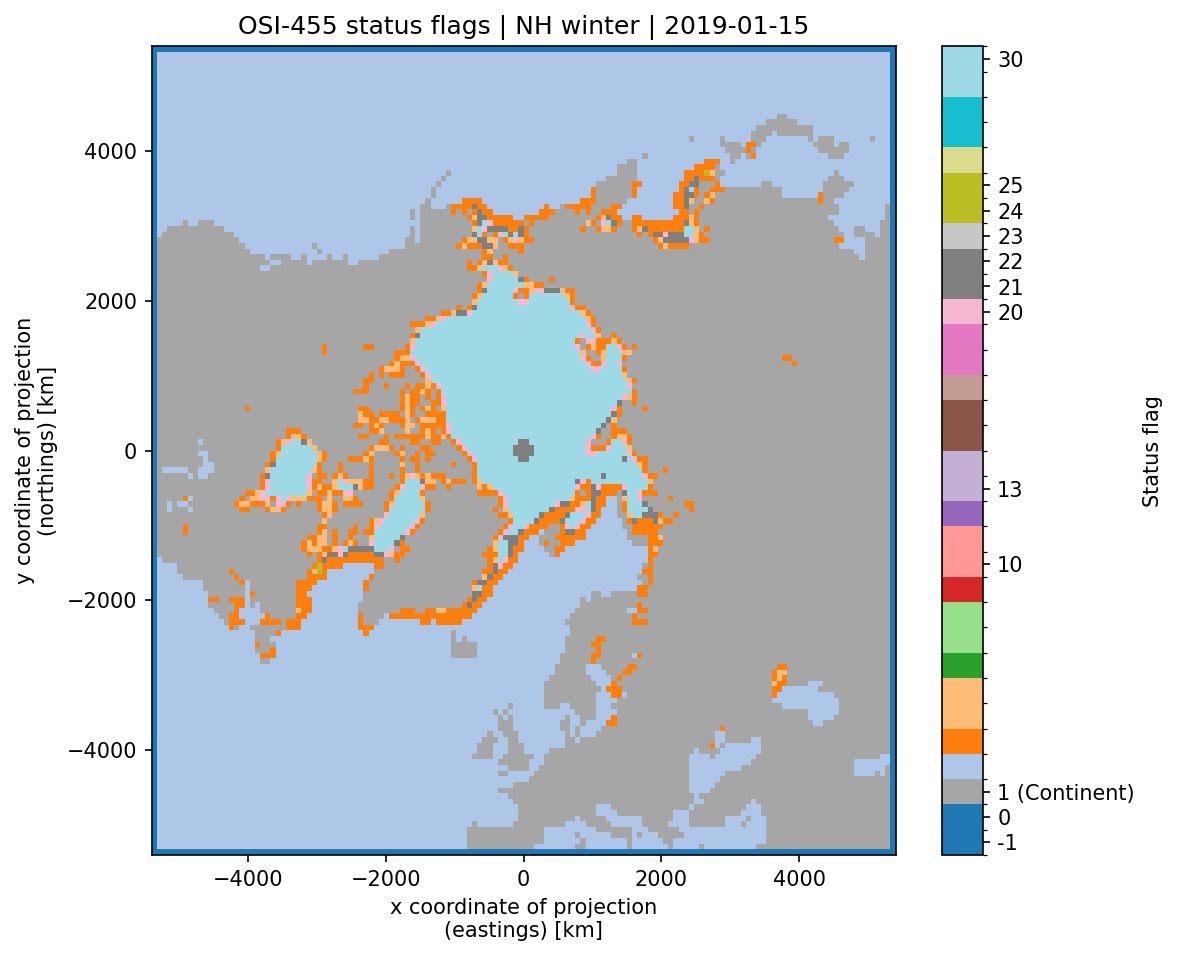

In [15]:
# Flag samples have their own dates and datasets; obs_raw remains the inspection sample.
flag_winter_date = "2019-01-15" if inspect_hem == "nh" else "2019-07-15"
if "obs_winter_raw" in globals():
    obs_winter_raw.close()
obs_winter_raw, flag_winter_path = open_flag_sample(inspect_hem, flag_winter_date)
if show_details:
    print("Winter flag source:", flag_winter_path)
plot_status_flag(obs_winter_raw, "winter", inspect_hem, flag_winter_date)


In [16]:
flag_summer_date = "2019-07-15" if inspect_hem == "nh" else "2019-01-15"
if "obs_summer_raw" in globals():
    obs_summer_raw.close()
obs_summer_raw, flag_summer_path = open_flag_sample(inspect_hem, flag_summer_date)
if show_details:
    print("Summer flag source:", flag_summer_path)


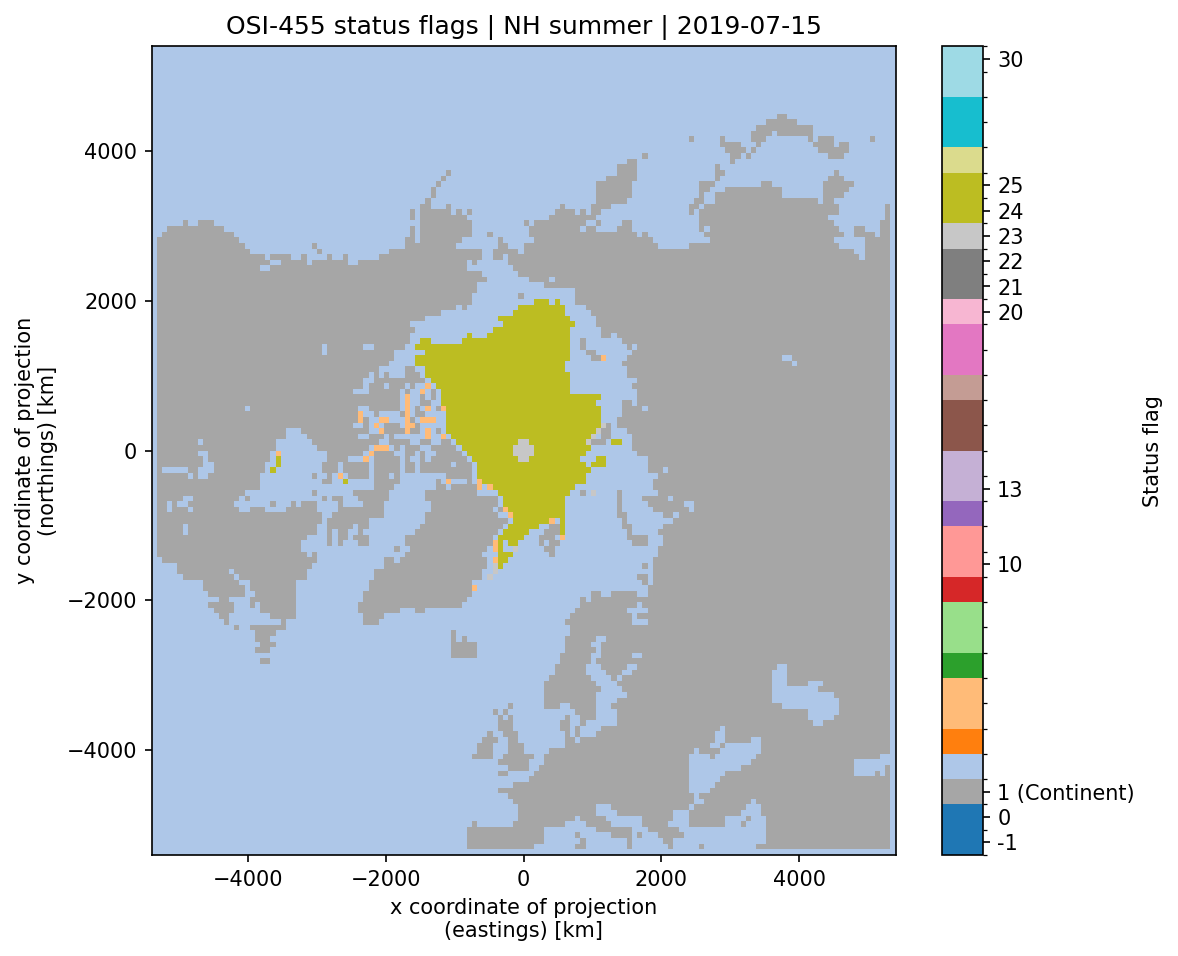

In [17]:
plot_status_flag(obs_summer_raw, "summer", inspect_hem, flag_summer_date)
# The model and native-grid view still follow inspect_date, not the seasonal flag dates.
assert Path(obs_raw.encoding["source"]) == obs_path
assert inspect_stamp == pd.Timestamp(inspect_date)
if show_details:
    print("Native-grid inspection remains:", inspect_hem, inspect_date)


In [18]:
with nullcontext() if show_details else capture_output():
    # Locate the original monthly CICE file through the same intake-esm datastore.
    raw_catalog = catalog(args)
    raw_months = month_rows(raw_catalog.search(
        realm="seaIce", frequency="1mon", variable=["uvel_m", "vvel_m", "aice_m"]), inspect_stamp.year)
    raw_row = raw_months.loc[raw_months.month == inspect_stamp.to_period("M")]
    if len(raw_row) != 1:
        raise ValueError("Expected exactly one matching monthly CICE source")
    model_path = Path(raw_row.iloc[0]["path"])
    if "model_raw" in globals():
        model_raw.close()
    model_raw = selected_file(raw_catalog, model_path,
                                   ["uvel_m", "vvel_m", "aice_m", "ANGLE"], "1mon")
    if show_details:
        print("MODEL source:", model_path)
    if show_details:
        print("Raw model grid, before rotation/regridding; monthly mean, not daily.")
    if show_details:
        display(model_raw)
    if show_details:
        display(pd.DataFrame([
            {"variable": name, "dims": str(model_raw[name].dims),
             "units": model_raw[name].attrs.get("units", ""),
             "description": model_raw[name].attrs.get("long_name", "")}
            for name in ("uvel_m", "vvel_m", "aice_m", "ANGLE")
        ]))
    if "model_interval_start" in model_raw.coords:
        if show_details:
            print("MODEL interval:", model_raw.model_interval_start.values, "to", model_raw.model_interval_end.values)
    # Keep datasets available for inspection; close them with obs_raw.close(); model_raw.close().


### Plot both sources on their original grids (no regridding)

Run the observation/model opening cells above, then these two cells. The upper
panels show speed and geographic east/north arrows at the original grid centres:
OSI-455 daily displacement-equivalent rates and OM3 monthly velocity. Model
vectors are rotated using ANGLE **without moving any grid point**. Coloured
markers represent native centres, not reconstructed cell polygons or area means.
Arrow thinning affects display only; no interpolation or common target grid is used.

The lower panels show the same geographic zoom: the OSI-455 centre lattice and
the OM3 U/T centre locations. Connecting lines follow centre indices, not cell
boundaries. OM3 U points use their own ocean mask; T points use the T mask.
The source velocity map does not interpolate T-grid SIC onto U points or apply
the later paired-analysis SIC mask. Observation quality defaults to nominal
(flag 30); change `source_obs_quality` if required. Missing observations stay
blank. These different sampling windows and masks make this an inspection,
**not a paired bias calculation**. `inspect_hem` and `inspect_date` control the
selected sources; use a suitable winter date for nominal satellite coverage.
This figure is supplementary and does not change Figures 1-4 or the Arctic checks.


In [19]:
def finite_line_segments(x, y):
    """Yield contiguous, finite geographic segments; never bridge gaps or seams."""
    import numpy as np
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    if x.ndim != 1 or x.shape != y.shape:
        raise ValueError("Expected matching one-dimensional coordinate arrays")
    good = np.isfinite(x) & np.isfinite(y) & (abs(y) <= 90) & (abs(x) <= 180)
    indices = np.flatnonzero(good)
    if indices.size < 2:
        return
    breaks = np.flatnonzero((np.diff(indices) != 1) | (abs(np.diff(x[indices])) > 180))+1
    for run in np.split(indices, breaks):
        if run.size >= 2:
            yield x[run], y[run]

with nullcontext() if show_details else capture_output():
    import warnings
    # Display controls: change these directly; all scientific values stay on their native grids.
    source_obs_quality = "nominal"  # nominal, satellite, wind, or all
    source_obs_arrow_step = 3
    source_model_arrow_step = 18
    source_arrow_scale = 2.8
    source_zoom_extent = (-15, 15, 75, 82) if inspect_hem == "nh" else (-15, 15, -70, -60)

    import cartopy.crs as ccrs
    import cartopy.feature as cfeature
    from IPython.display import Image, display
    if source_obs_quality not in QUALITY:
        raise ValueError("Unknown observation quality selection")
    if min(source_obs_arrow_step, source_model_arrow_step) < 1 or source_arrow_scale <= 0:
        raise ValueError("Arrow steps and scale must be positive")

    # Original OSI-455 coordinates and geodesic displacement-equivalent rates.
    # The displacement conversion is shown in the methods section below.
    source_obs_lon = np.asarray(obs_raw.lon)
    source_obs_lat = np.asarray(obs_raw.lat)
    source_obs_u, source_obs_v, source_obs_duration, source_obs_fallback = displacement_rate(obs_raw)
    source_obs_flag = np.asarray(obs_raw.status_flag.isel(time=0))
    source_obs_keep = (np.isfinite(source_obs_u) & np.isfinite(source_obs_v)
                       & np.isin(source_obs_flag, QUALITY[source_obs_quality]))
    source_obs_speed = np.where(source_obs_keep, np.hypot(source_obs_u, source_obs_v), np.nan)
    assert source_obs_speed.shape == obs_raw.lon.shape

    # Load the model's own U/T coordinates and masks; do not use remapped caches.
    source_static_catalog = raw_catalog.search(realm="seaIce", frequency="fx",
                                               variable=["ULON", "ULAT", "TLON", "TLAT"])
    source_static_path = Path(source_static_catalog.df.path.iloc[0])
    if "source_grid_raw" in globals():
        source_grid_raw.close()
    source_grid_raw = selected_file(raw_catalog, source_static_path,
                                        ["ULON", "ULAT", "TLON", "TLAT", "umask", "tmask"], "fx").load()
    source_model_lon = source_grid_raw.ULON.values
    source_model_lat = source_grid_raw.ULAT.values
    source_t_lon, source_t_lat = source_grid_raw.TLON.values, source_grid_raw.TLAT.values
    source_grid_u = model_raw.uvel_m.isel(time=0).values
    source_grid_v = model_raw.vvel_m.isel(time=0).values
    source_angle = model_raw.ANGLE.values
    # Rotation changes direction components only, never positions or speed magnitude.
    source_model_u = source_grid_u*np.cos(source_angle)-source_grid_v*np.sin(source_angle)
    source_model_v = source_grid_u*np.sin(source_angle)+source_grid_v*np.cos(source_angle)
    source_model_keep = ((source_grid_raw.umask.values > 0)
                         & np.isfinite(source_model_lon) & np.isfinite(source_model_lat)
                         & np.isfinite(source_model_u) & np.isfinite(source_model_v))
    source_model_speed = np.where(source_model_keep, np.hypot(source_model_u, source_model_v), np.nan)
    assert source_model_speed.shape == model_raw.uvel_m.shape[-2:] == source_model_lon.shape
    source_rotation_valid = np.isfinite(source_angle) & np.isfinite(source_grid_u) & np.isfinite(source_grid_v)
    np.testing.assert_allclose(np.hypot(source_model_u, source_model_v)[source_rotation_valid],
                               np.hypot(source_grid_u, source_grid_v)[source_rotation_valid], rtol=1e-6, atol=1e-8)
    source_sign = 1 if inspect_hem == "nh" else -1
    source_obs_region = (source_sign*source_obs_lat >= 45) & np.isfinite(source_obs_lon)
    source_model_region = (source_sign*source_model_lat >= 45) & np.isfinite(source_model_lon)
    source_obs_visible = source_obs_region & np.isfinite(source_obs_speed)
    source_model_visible = source_model_region & np.isfinite(source_model_speed)
    if show_details:
        print("Original OBS grid:", source_obs_speed.shape, "| Original OM3 U grid:", source_model_speed.shape)
    if show_details:
        print("Source windows: OBS 24-hour endpoint product ending", inspect_date,
              "| OM3 full calendar month", f"{inspect_stamp:%Y-%m}")
    if show_details:
        print("No regridding, interpolation or area averaging is performed in this inspection.")


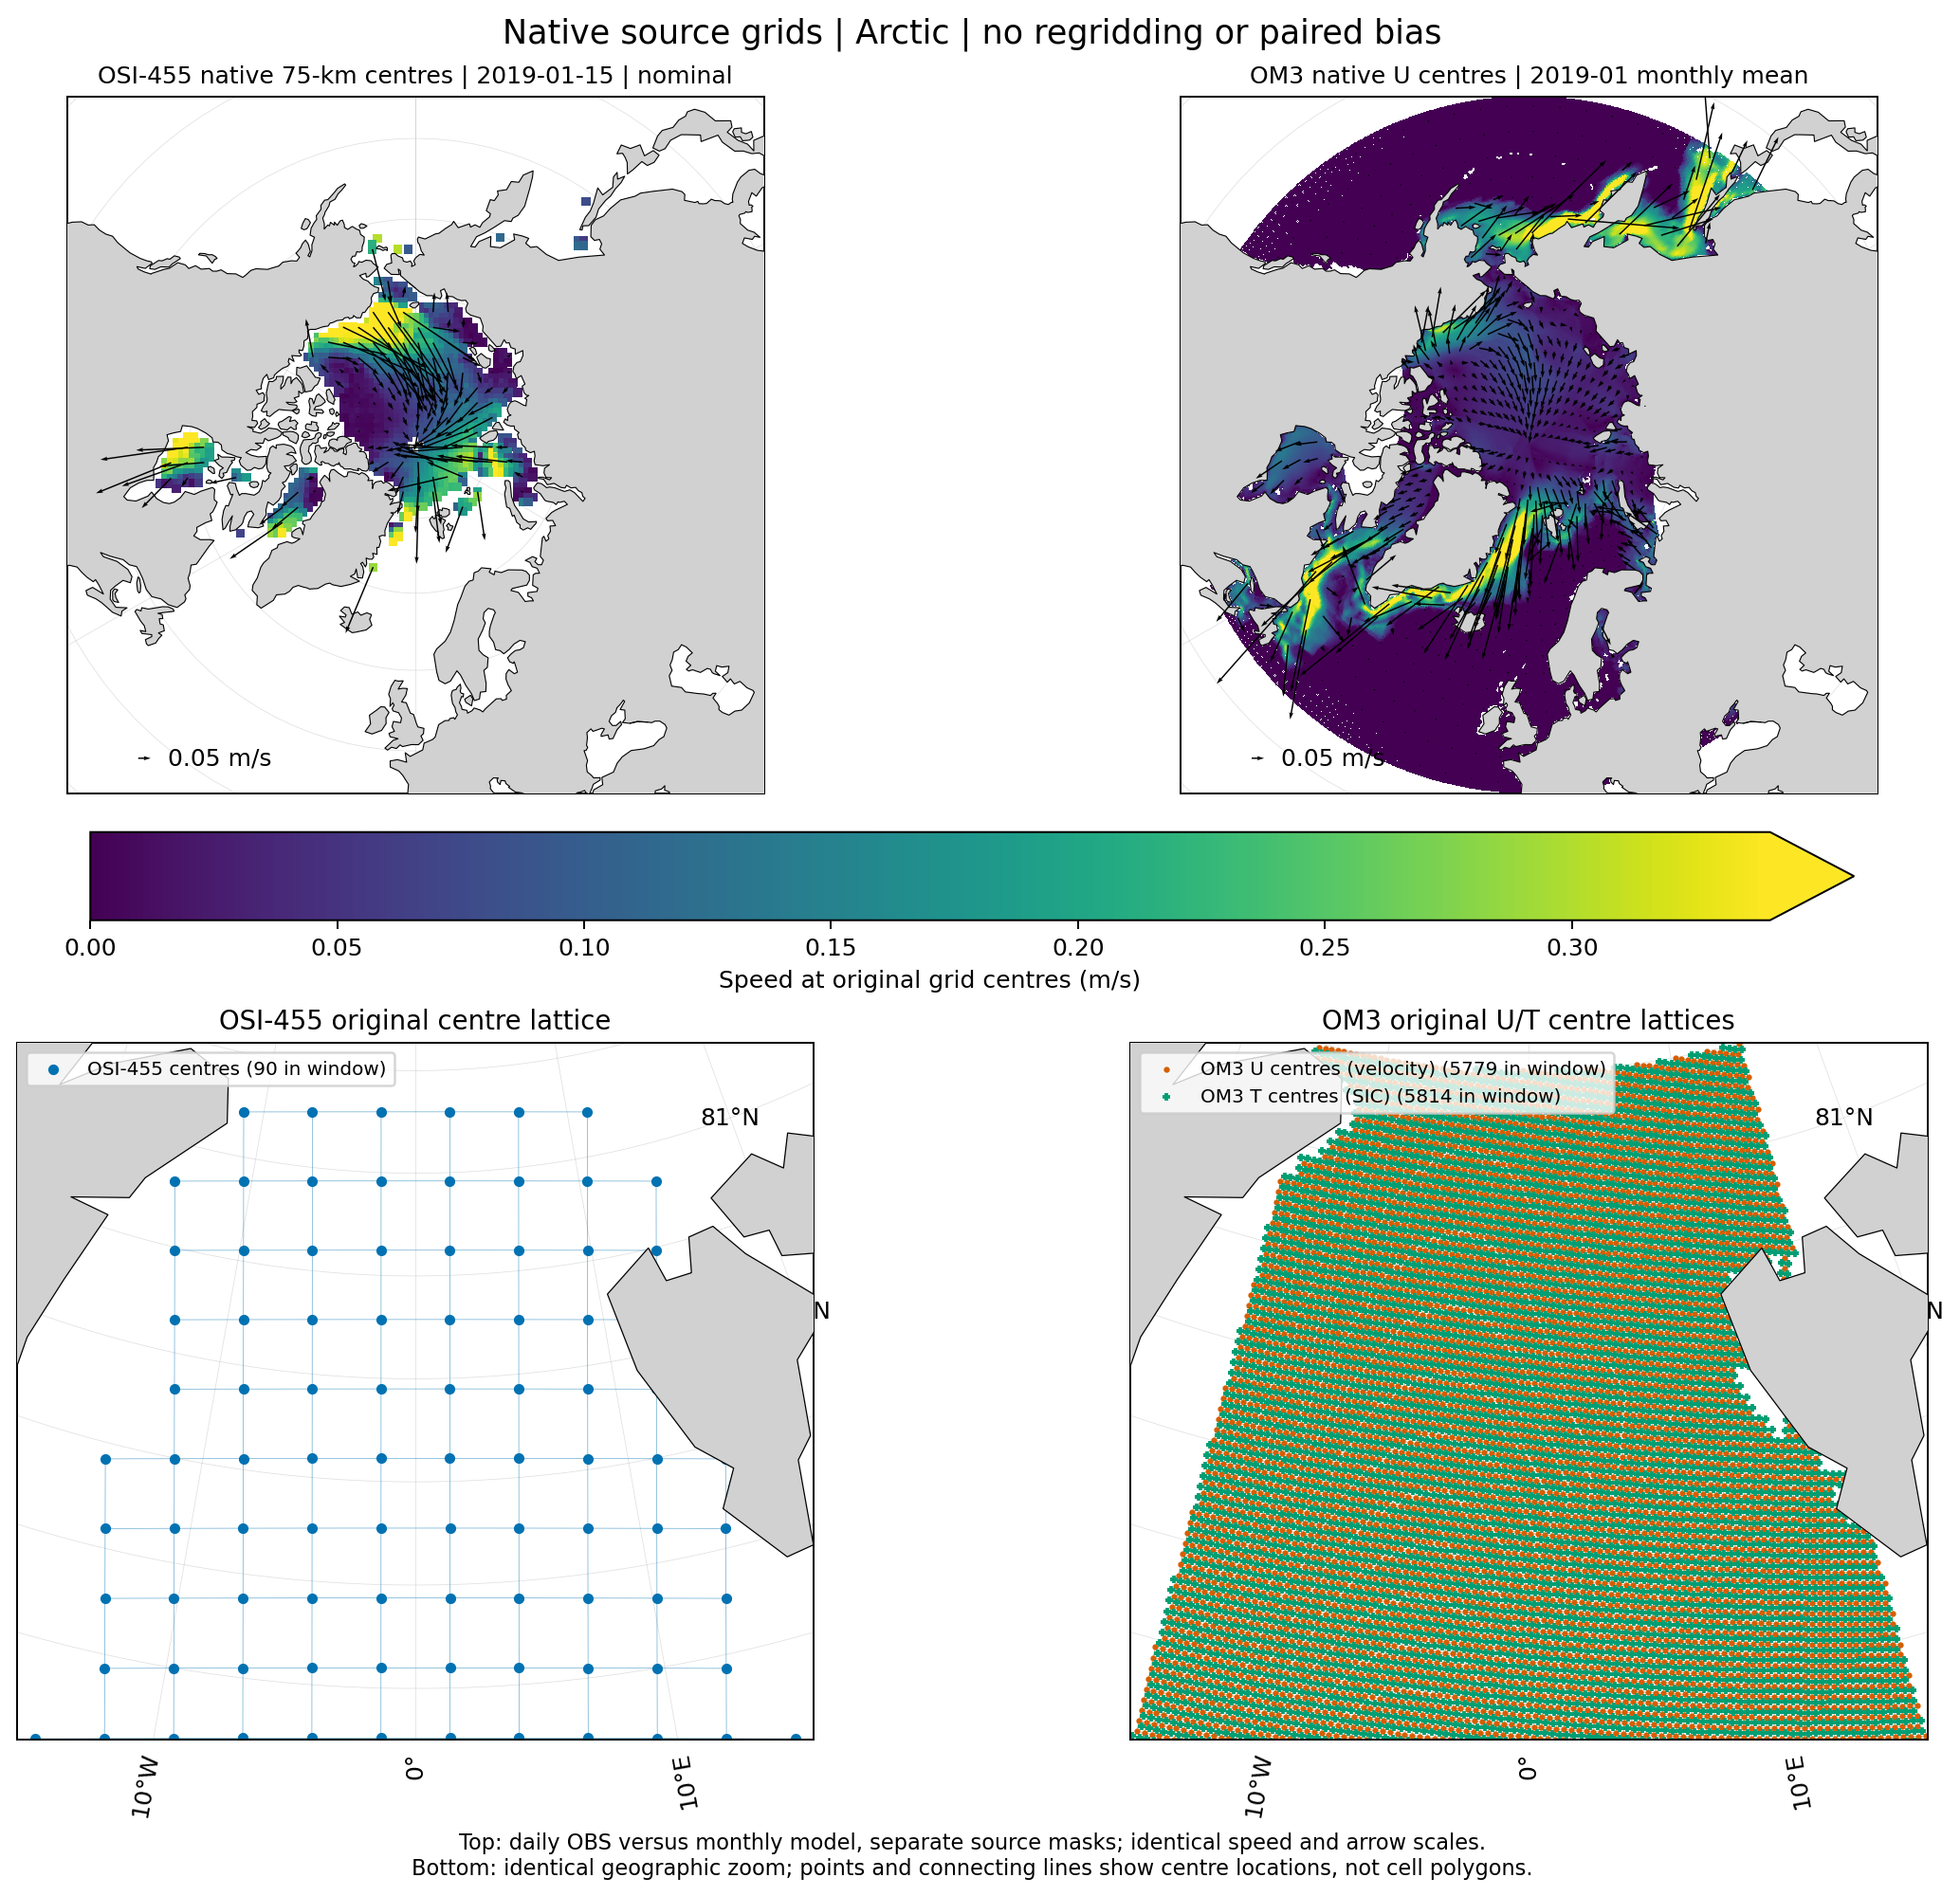

In [20]:
# Native-grid source inspection: every plotting command is explicit in this cell.
source_projection = ccrs.NorthPolarStereo() if inspect_hem == "nh" else ccrs.SouthPolarStereo()
source_cap_extent = [-180, 180, 45, 90] if inspect_hem == "nh" else [-180, 180, -90, -45]
source_pole_name = "Arctic" if inspect_hem == "nh" else "Antarctic"
source_values = np.r_[source_obs_speed[source_obs_visible], source_model_speed[source_model_visible]]
source_vmax = max(.03, float(np.quantile(source_values, .98))) if source_values.size else .1
source_fig = plt.figure(figsize=(13, 11), constrained_layout=True)
source_specs = source_fig.add_gridspec(2, 2)
source_axes = []

for source_col, (source_lon, source_lat, source_u, source_v, source_speed, source_valid,
                 source_step, source_label, source_marker_size) in enumerate([
    (source_obs_lon, source_obs_lat, source_obs_u, source_obs_v, source_obs_speed,
     source_obs_visible, source_obs_arrow_step,
     f"OSI-455 native 75-km centres | {inspect_date} | {source_obs_quality}", 14),
    (source_model_lon, source_model_lat, source_model_u, source_model_v, source_model_speed,
     source_model_visible, source_model_arrow_step,
     f"OM3 native U centres | {inspect_stamp:%Y-%m} monthly mean", .6)]):
    source_ax = source_fig.add_subplot(source_specs[0, source_col], projection=source_projection)
    source_ax.set_extent(source_cap_extent, ccrs.PlateCarree())
    source_ax.add_feature(cfeature.LAND.with_scale("110m"), facecolor="0.82", zorder=3)
    source_ax.coastlines(resolution="110m", linewidth=.45, zorder=4)
    source_ax.gridlines(linewidth=.3, alpha=.4)
    source_im = source_ax.scatter(source_lon[source_valid], source_lat[source_valid],
                                  c=source_speed[source_valid], s=source_marker_size, marker="s",
                                  cmap="viridis", vmin=0, vmax=source_vmax, edgecolors="none",
                                  transform=ccrs.PlateCarree(), rasterized=True, zorder=2)
    source_thin = np.s_[::source_step, ::source_step]
    source_arrow_valid = source_valid[source_thin]
    source_quiver = source_ax.quiver(source_lon[source_thin][source_arrow_valid],
                                    source_lat[source_thin][source_arrow_valid],
                                    source_u[source_thin][source_arrow_valid],
                                    source_v[source_thin][source_arrow_valid],
                                    transform=ccrs.PlateCarree(), scale=source_arrow_scale,
                                    scale_units="width", width=.002, color="black", zorder=5)
    source_ax.quiverkey(source_quiver, .12, .05, .05, "0.05 m/s", coordinates="axes", labelpos="E")
    if not source_valid.any():
        source_ax.text(.5, .5, "No accepted observations for this selection", ha="center",
                       transform=source_ax.transAxes)
    source_ax.set_title(source_label, fontsize=10)
    source_axes.append(source_ax)
source_fig.colorbar(source_im, ax=source_axes, orientation="horizontal", shrink=.8,
                    label="Speed at original grid centres (m/s)", extend="max")

source_west, source_east, source_south, source_north = source_zoom_extent
if not (source_west < source_east and source_south < source_north):
    raise ValueError("Use increasing zoom bounds without crossing the longitude seam")
for source_col in (0, 1):
    source_ax = source_fig.add_subplot(source_specs[1, source_col], projection=source_projection)
    source_ax.set_extent(source_zoom_extent, ccrs.PlateCarree())
    source_ax.add_feature(cfeature.LAND.with_scale("110m"), facecolor="0.82", zorder=3)
    source_ax.coastlines(resolution="110m", linewidth=.5, zorder=4)
    source_gridliner = source_ax.gridlines(draw_labels=True, linewidth=.3, alpha=.4)
    source_gridliner.top_labels = False
    source_gridliner.right_labels = False
    if source_col == 0:
        source_lattices = [(source_obs_lon, source_obs_lat, np.isfinite(source_obs_lon),
                            "OSI-455 centres", "#0072B2", "o", True)]
    else:
        source_lattices = [(source_model_lon, source_model_lat, source_grid_raw.umask.values > 0,
                            "OM3 U centres (velocity)", "#D55E00", ".", True),
                           (source_t_lon, source_t_lat, source_grid_raw.tmask.values > 0,
                            "OM3 T centres (SIC)", "#009E73", "+", False)]
    for source_lon, source_lat, source_ocean, source_label, source_color, source_marker, source_lines in source_lattices:
        source_normal_lon = (source_lon+180) % 360-180
        source_zoom_mask = (source_ocean & np.isfinite(source_normal_lon) & np.isfinite(source_lat)
                            & (source_normal_lon >= source_west) & (source_normal_lon <= source_east)
                            & (source_lat >= source_south) & (source_lat <= source_north))
        if source_lines:
            source_line_lon = np.where(source_zoom_mask, source_normal_lon, np.nan)
            source_line_lat = np.where(source_zoom_mask, source_lat, np.nan)
            # Connect neighbouring native centres only; do not infer cell bounds.
            for source_line_x, source_line_y in ((source_line_lon, source_line_lat),
                                                (source_line_lon.T, source_line_lat.T)):
                for source_x, source_y in zip(source_line_x, source_line_y):
                    for source_segment_x, source_segment_y in finite_line_segments(source_x, source_y):
                        assert np.isfinite(source_segment_x).all() and np.isfinite(source_segment_y).all()
                        with warnings.catch_warnings():
                            warnings.filterwarnings("error", message="invalid value encountered in linestrings",
                                                    category=RuntimeWarning)
                            source_ax.plot(source_segment_x, source_segment_y, color=source_color, lw=.3, alpha=.55,
                                           transform=ccrs.PlateCarree(), zorder=2)
        source_ax.scatter(source_normal_lon[source_zoom_mask], source_lat[source_zoom_mask],
                          s=12 if source_col == 0 else 9, marker=source_marker, color=source_color,
                          transform=ccrs.PlateCarree(), rasterized=True, zorder=2,
                          label=f"{source_label} ({int(source_zoom_mask.sum())} in window)")
    source_ax.legend(loc="upper left", fontsize=8)
    source_ax.set_title("OSI-455 original centre lattice" if source_col == 0 else "OM3 original U/T centre lattices",
                        fontsize=11)

source_fig.suptitle(f"Native source grids | {source_pole_name} | no regridding or paired bias", fontsize=14)
source_fig.supxlabel("Top: daily OBS versus monthly model, separate source masks; identical speed and arrow scales.\n"
                     "Bottom: identical geographic zoom; points and connecting lines show centre locations, not cell polygons.", fontsize=9)
source_inspection_root = output_root / "diagnostics/source_grids"
source_inspection_root.mkdir(parents=True, exist_ok=True)
source_inspection_stem = f"native_sources_{inspect_hem}_{inspect_stamp:%Y%m%d}"
source_inspection_png = source_inspection_root / f"{source_inspection_stem}.png"
with warnings.catch_warnings():
    warnings.filterwarnings("error", message="invalid value encountered in linestrings", category=RuntimeWarning)
    source_fig.savefig(source_inspection_png, dpi=180, bbox_inches="tight", facecolor="white")
    source_fig.savefig(source_inspection_png.with_suffix(".pdf"), bbox_inches="tight", facecolor="white")
plt.close(source_fig)
display(Image(filename=str(source_inspection_png)))
write_json(source_inspection_root / "latest.json",
                dict(hemisphere=inspect_hem, date=inspect_date, observation=str(obs_path), model=str(model_path),
                     static_grid=str(source_static_path), observation_shape=list(source_obs_speed.shape),
                     model_u_shape=list(source_model_speed.shape), model_t_shape=list(source_t_lon.shape),
                     quality=source_obs_quality, observation_valid_centres=int(source_obs_visible.sum()),
                     model_valid_centres=int(source_model_visible.sum()), zoom_extent=list(source_zoom_extent),
                     regridded=False, units="m/s", image=str(source_inspection_png),
                     note="Daily observation versus monthly model; native centres, separate masks; not a paired bias calculation"))
if show_details:
    print("Native-grid inspection saved:", source_inspection_png)


## Methods

### Endpoint conversion and model-vector rotation

The source `lat/lon` locate the ice at t0, and `lat1/lon1` locate it at t1.
Use WGS84 geodesic distance and the initial azimuth, divided by each cell's
decoded t1−t0. Missing cell times fall back to the nominal noon-to-noon bounds,
and their count is recorded. An independent check projects both endpoints and
compares their difference with archived `dX/dY`, verifying sign and origin.

The 75 km EASE2 Lambert azimuthal equal-area grid is not conformal. A simple
polar-stereographic convergence-angle rotation is therefore not reused.
Model `ANGLE` is in radians; `uvel_m/vvel_m` are already m/s.


In [21]:
def displacement_rate(ds):
    """PUM §4.2: lat/lon are start positions; lat1/lon1 are endpoints.

    WGS84 geodesic distance and initial bearing define a displacement-equivalent
    east/north rate at the start position. It does not prescribe a trajectory.
    t0/t1 are decoded per-cell sensing times; fall back to nominal bounds only
    where the per-cell interval is unavailable, with a saved fallback count.
    """
    azimuth, _, distance = GEOD.inv(ds.lon.values, ds.lat.values,
                                  ds.lon1.isel(time=0).values, ds.lat1.isel(time=0).values)
    nominal = float((ds.time_bnds.values.ravel()[1] - ds.time_bnds.values.ravel()[0]) / np.timedelta64(1, "s"))
    if not np.isclose(nominal, 86400):
        raise ValueError(f"Unexpected nominal OSI interval: {nominal}")
    duration = np.asarray((ds.t1.isel(time=0).values - ds.t0.isel(time=0).values) / np.timedelta64(1, "s"), dtype=float)
    fallback = ~np.isfinite(duration) | (duration <= 0)
    duration = np.where(fallback, nominal, duration)
    speed = distance / duration
    bearing = np.deg2rad(azimuth)
    return speed * np.sin(bearing), speed * np.cos(bearing), duration, fallback

In [22]:
def rotate_model(u, v, angle):
    return u * np.cos(angle) - v * np.sin(angle), u * np.sin(angle) + v * np.cos(angle)

### Quality selection, common mask, and metrics

Nominal: flag 30. Satellite sensitivity: 20,21,22,30. Wind-related: 23,24,25.
All combines these categories. Flag 30 is the primary validation; 21/22 are
interpolated/corrected and lower quality. Wind-filled/blended summer data are
not independent satellite validation. Native quality control already rejects
land, open water, and near-coast/edge retrievals (flags below 20).

A cell-month requires ≥50% of calendar days and ≥5 accepted days, model SIC
≥15%, and finite paired components. Group observations by endpoint month.
Regrid rotated model U-grid vectors and T-grid SIC separately with bilinear
weights. Use true coordinates and preserve invalid source masks.

Speed means the magnitude of a monthly mean vector, not the monthly average
of daily speed. Metrics use area × model SIC × calendar-month duration weights. Direction
errors require both rates ≥0.01 m/s. Stored mean projected uncertainty is not
treated as a monthly standard error; temporal/spatial error correlation is unresolved.


In [23]:
def common_mask(ds, args):
    required = np.maximum(args.min_days, np.ceil(ds.time.dt.days_in_month * args.min_fraction))
    return ((ds.n_obs >= required) & (ds.aice_model >= args.sic_threshold)
            & np.isfinite(ds.u_obs) & np.isfinite(ds.v_obs)
            & np.isfinite(ds.u_model) & np.isfinite(ds.v_model)
            & (abs(ds.lat) >= 45))

In [24]:
def weighted_metrics(ds, args):
    mask = common_mask(ds, args)
    w = (ds.cell_area * ds.aice_model * ds.time.dt.days_in_month).broadcast_like(ds.u_obs).where(mask, 0).values
    valid = w > 0
    count = int(valid.sum())
    empty = dict(n_grid_months=0, obs_mean=np.nan, model_mean=np.nan, speed_bias=np.nan,
                 speed_mae=np.nan, speed_rmse=np.nan, vector_rmse=np.nan,
                 u_correlation=np.nan, v_correlation=np.nan, direction_mae_deg=np.nan)
    if not count:
        return empty
    w = w[valid].astype(float)
    w /= w.sum()
    # Broadcast model to quality only when necessary; callers select one quality.
    uo, vo, um, vm = [np.asarray(ds[n].broadcast_like(ds.u_obs))[valid] for n in ("u_obs", "v_obs", "u_model", "v_model")]
    so, sm = np.hypot(uo, vo), np.hypot(um, vm)
    bias, du, dv = sm - so, um - uo, vm - vo
    def corr(a, b):
        a, b = a - np.sum(w * a), b - np.sum(w * b)
        denominator = np.sqrt(np.sum(w * a * a) * np.sum(w * b * b))
        return float(np.sum(w * a * b) / denominator) if denominator > 0 else np.nan
    fast = (so >= args.direction_floor) & (sm >= args.direction_floor)
    direction = np.nan
    if fast.any():
        error = abs(np.angle(np.exp(1j * (np.arctan2(vm[fast], um[fast]) - np.arctan2(vo[fast], uo[fast])))))
        direction = float(np.rad2deg(np.average(error, weights=w[fast])))
    return dict(n_grid_months=count, obs_mean=float(np.sum(w * so)), model_mean=float(np.sum(w * sm)),
                speed_bias=float(np.sum(w * bias)), speed_mae=float(np.sum(w * abs(bias))),
                speed_rmse=float(np.sqrt(np.sum(w * bias**2))), vector_rmse=float(np.sqrt(np.sum(w * (du**2 + dv**2)))),
                u_correlation=corr(uo, um), v_correlation=corr(vo, vm), direction_mae_deg=direction)

### Velocity strength and circular turning statistics

For local east/north components, the signed angle from observation to model is
`atan2(u_obs*v_model - v_obs*u_model, u_obs*u_model + v_obs*v_model)`.
The regional signed mean is `atan2(weighted_mean(sin(angle)), weighted_mean(cos(angle)))`,
not an arithmetic average of degrees. The resultant length R measures circular
concentration; the plot suppresses signed means below the configured R threshold.


In [25]:
def velocity_cycle_metrics(ds, args):
    """Pool paired cell-months, never the spatially averaged velocity vector.

    Positive turning is counterclockwise from observation to model in the
    local east/north basis. Circular resultant length R diagnoses cancellation;
    it is concentration, not a confidence interval.
    """
    records = []
    for month in range(1, 13):
        field = ds.sel(time=ds.time.dt.month == month)
        mask = common_mask(field, args)
        w = (field.cell_area * field.aice_model * field.time.dt.days_in_month).broadcast_like(field.u_obs).where(mask, 0).values
        valid = w > 0
        count = int(valid.sum())
        row = dict(month=month, n_grid_months=count, n_direction=0,
                   n_years=int(mask.any(["yc", "xc"]).sum().item()),
                   paired_weight_m2_days=float(w.sum()), direction_weight_m2_days=0.,
                   obs_mean=np.nan, model_mean=np.nan, turning_angle_deg=np.nan,
                   direction_mae_deg=np.nan, direction_resultant=np.nan,
                   direction_weight_fraction=np.nan)
        if count:
            weights = w[valid].astype(float)
            uo, vo, um, vm = [np.asarray(field[n].broadcast_like(field.u_obs))[valid]
                              for n in ("u_obs", "v_obs", "u_model", "v_model")]
            so, sm = np.hypot(uo, vo), np.hypot(um, vm)
            row.update(obs_mean=float(np.average(so, weights=weights)),
                       model_mean=float(np.average(sm, weights=weights)))
            fast = (so >= args.direction_floor) & (sm >= args.direction_floor)
            row["n_direction"] = int(fast.sum())
            row["direction_weight_m2_days"] = float(weights[fast].sum())
            row["direction_weight_fraction"] = float(weights[fast].sum() / weights.sum())
            if fast.any():
                # atan2(cross, dot) has the desired sign and handles ±180°.
                delta = np.arctan2(uo[fast] * vm[fast] - vo[fast] * um[fast],
                                   uo[fast] * um[fast] + vo[fast] * vm[fast])
                s = np.average(np.sin(delta), weights=weights[fast])
                c = np.average(np.cos(delta), weights=weights[fast])
                resultant = float(np.hypot(s, c))
                row.update(direction_resultant=resultant,
                           turning_angle_deg=float(np.rad2deg(np.arctan2(s, c))) if resultant > 1e-12 else np.nan,
                           direction_mae_deg=float(np.average(np.rad2deg(abs(delta)), weights=weights[fast])))
        records.append(row)
    return pd.DataFrame(records)

In [26]:
def annual_velocity_metrics(cycle):
    """Recover pooled annual climatology from weighted monthly moments.

    Circular moments must include each month's resultant R. Averaging monthly
    angles alone would incorrectly give diffuse and concentrated months equal
    influence. These are relative-bias summary arrows, not bulk transport.
    """
    records = []
    if not cycle.quality.eq("nominal").all() or cycle.duplicated(["hemisphere", "month"]).any():
        raise ValueError("Expected unique nominal calendar-month records")
    for hem, rows in cycle.groupby("hemisphere", sort=True):
        valid = rows.paired_weight_m2_days > 0
        if not valid.any():
            raise ValueError(f"No valid paired samples for {hem}")
        weights = rows.loc[valid, "paired_weight_m2_days"]
        obs = float(np.average(rows.loc[valid, "obs_mean"], weights=weights))
        model = float(np.average(rows.loc[valid, "model_mean"], weights=weights))
        direction = rows.direction_weight_m2_days > 0
        angle, resultant, mae = np.nan, np.nan, np.nan
        if direction.any():
            d = rows.loc[direction]
            w = d.direction_weight_m2_days.to_numpy()
            theta = np.deg2rad(d.turning_angle_deg.fillna(0).to_numpy())
            # An exactly cancelled month has undefined angle and R≈0.
            r = d.direction_resultant.to_numpy()
            s = np.average(r * np.sin(theta), weights=w)
            c = np.average(r * np.cos(theta), weights=w)
            resultant = float(np.hypot(s, c))
            if resultant > 1e-12:
                angle = float(np.rad2deg(np.arctan2(s, c)))
            mae = float(np.average(d.direction_mae_deg, weights=w))
        records.append(dict(hemisphere=hem, quality="nominal", obs_mean=obs,
                            model_mean=model, speed_bias=model-obs,
                            turning_angle_deg=angle, direction_resultant=resultant,
                            direction_mae_deg=mae, n_grid_months=int(rows.n_grid_months.sum()),
                            n_direction=int(rows.n_direction.sum()),
                            covered_calendar_months=int(valid.sum())))
    return pd.DataFrame(records)

## Validation

### Cache provenance and completeness

In [27]:
record_path = output_root / "manifests/aggregate.json"
if not record_path.exists():
    raise FileNotFoundError(f"No evaluated cache for {experiment}: {output_root}. Set output_root to its matching cache or recompute=True on Gadi.")
record = json.loads(record_path.read_text())
assert record["status"] == "complete"
assert record["signature"] == signature(args), "Saved products do not match experiment, mask, or QC parameters."
assert record["start_year"] == start_year and record["end_year"] == end_year
if show_details:
    print("Validated cache:", output_root)
if show_details:
    print("Experiment:", experiment, "| Period:", start_year, "to", end_year)
if show_details:
    print("Signature:", record["signature"])
metrics = pd.read_csv(output_root / "tables/metrics.csv")
monthly = pd.read_csv(output_root / "tables/monthly_timeseries.csv", parse_dates=["time"])
assert len(monthly) == 2 * len(QUALITY) * (end_year-start_year+1) * 12

if show_daily_pilot:
    daily = pd.read_csv(output_root / "tables/daily_pilot_metrics.csv")
    daily_table = daily.query("quality == 'nominal'").rename(columns={"n_grid_months": "n_grid_cells"})
    mkmd.table("Daily-window pilot", daily_table.round(5).to_markdown(index=False).split("\n"))
    display(daily_table)

print("Cache checks passed.")


Cache checks passed.


### Formula replay on saved paired fields

In [28]:
if replay_metric:
    with nullcontext() if show_details else capture_output():
        paired = load_matched(args, "sh").sel(quality="nominal")
        actual = weighted_metrics(paired, args)
        expected = metrics.query("hemisphere == 'sh' and quality == 'nominal' and period == 'full' and season == 'ALL'").iloc[0]
        for name, value in actual.items():
            np.testing.assert_allclose(value, expected[name], rtol=1e-6, atol=1e-10, equal_nan=True)
        replay_cycle = velocity_cycle_metrics(paired, args)
        archived_cycle = pd.read_csv(output_root / "tables/velocity_turning_cycle.csv").query("hemisphere == 'sh'").reset_index(drop=True)
        for name in replay_cycle:
            np.testing.assert_allclose(replay_cycle[name], archived_cycle[name], rtol=1e-6, atol=1e-10, equal_nan=True)
        paired.close()
        del paired
        print("Visible formulas reproduce the archived Southern Hemisphere nominal metrics.")
        print("Visible circular-turning formulas reproduce the archived Southern Hemisphere cycle.")
    if not show_details:
        print("Formula checks passed.")


Formula checks passed.


## Main results

### Nominal full-period metrics

In [29]:
metric_columns = ["hemisphere", "quality", "period", "n_grid_months", "speed_bias",
                  "speed_rmse", "vector_rmse", "u_correlation", "v_correlation", "direction_mae_deg"]
table = metrics.query("season == 'ALL' and quality == 'nominal' and period == 'full'")[metric_columns].reset_index(drop=True)
assert len(table) == 2 and set(table.hemisphere) == {"nh", "sh"}
with nullcontext() if show_details else capture_output():
    mkmd.table("OSI-455 drift-rate metrics", table.round(5).to_markdown(index=False).split("\n"))
display(table)
if show_source_sensitivity:
    sensitivity_table = metrics.query("season == 'ALL'")[metric_columns]
    mkmd.table("Source and period sensitivity", sensitivity_table.round(5).to_markdown(index=False).split("\n"))
    display(sensitivity_table)


,hemisphere,quality,period,n_grid_months,speed_bias,speed_rmse,vector_rmse,u_correlation,v_correlation,direction_mae_deg
0,nh,nominal,full,231469,0.017297,0.040161,0.048662,0.762653,0.842177,31.868598
1,sh,nominal,full,304849,0.032158,0.059135,0.066896,0.892444,0.774105,19.935802


### Figure overview

1. Figure 1: OBS/model sea-ice speed, paired speed bias and direction bias; 2 rows × 4 columns,
   Arctic above Antarctic, shared colour and quiver scales.
2. Figure 2: vertical annual mean speed and observation-relative turning sector
   diagram; three SIC rows (all paired, >80%, 15-80%) and two pole columns. OBS points UP; positive turning LEFT, negative RIGHT.
3. Figure 3: OBS versus model seasonal speed cycle; 2 rows × 1 column,
   Arctic above Antarctic. Missing calendar months remain gaps.
4. Figure 4: 1991–2020 yearly speeds and linear trends; 2 rows × 1 column,
   Arctic above Antarctic. Equal-year OLS slopes are in cm/s per decade.

All figures use nominal flag-30 paired observations and model, with the SAME
cell area × model SIC × month-duration weights. SIC ≥15% remains the mask.
No wind-derived data or interpolation fills summer gaps. Yearly means cover
available satellite-period samples, not complete 12-month observations.
Changing sampled area/months may affect trends; no significance claims or
independence-based confidence intervals are inferred. The coverage audit is in
`tables/annual_speed_timeseries.csv` and `manifests/speed_trends.json`.

The sector radius is mean cell-month speed, not the magnitude of a spatially
averaged velocity. Its angle is the circular mean local OBS-to-model turning,
NOT geographic direction or turning relative to wind. Monthly circular moments
retain their resultant R when pooled. Both speeds must be ≥0.01 m/s; R <0.1
hides an unstable arrow. Absolute angular error exposes cancellation. The two
summary arrows do not form a physical bulk velocity; endpoint separation is
not vector RMSE. Source inspection and intermediate QC tables are retained.

Figure 1 model panels b/f show model-SIC-valid spatial coverage independently of local OBS availability, but retain the same globally sampled nominal months. Speed-bias panels c/g and all scalar statistics still use paired cell-months; displayed unpaired model climatology minus OBS need not equal the bias panel.


In [30]:
# All figure helpers are defined in this notebook, not imported from plotting modules.
import hashlib
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from IPython.display import Image, display

def explicit_plot_hash():
    source_path = Path.cwd() / "51_si_drift_osi455.ipynb"
    saved = json.loads(source_path.read_text())
    blocks = [(c["id"], "".join(c["source"])) for c in saved["cells"]
              if c["cell_type"] == "code" and "explicit-plot" in c["metadata"].get("tags", [])]
    return hashlib.sha256(json.dumps(blocks, ensure_ascii=False).encode()).hexdigest()

def polar_axis(fig, spec, hem):
    projection = ccrs.NorthPolarStereo() if hem == "nh" else ccrs.SouthPolarStereo()
    ax = fig.add_subplot(spec, projection=projection)
    ax.set_extent([-180, 180, 45, 90] if hem == "nh" else [-180, 180, -90, -45], ccrs.PlateCarree())
    ax.add_feature(cfeature.LAND.with_scale("110m"), facecolor="0.82", zorder=3)
    ax.coastlines(resolution="110m", linewidth=.45, zorder=4)
    ax.gridlines(linewidth=.3, alpha=.4)
    return ax

def map_field(ax, ds, name, cmap, vmin, vmax):
    lon = (ds.lon.values + 180) % 360 - 180
    return ax.pcolormesh(lon, ds.lat.values, ds[name].values,
                         transform=ccrs.PlateCarree(), cmap=cmap, vmin=vmin, vmax=vmax,
                         shading="auto", rasterized=True)

def speed_trends(series):
    """Unweighted OLS over yearly means; no independence-based CI is inferred."""
    if series.duplicated(["hemisphere", "year"]).any():
        raise ValueError("Duplicate hemisphere/year in annual speeds")
    rows = []
    for hem, group in series.groupby("hemisphere", sort=True):
        for source in ("obs", "model"):
            valid = group[np.isfinite(group[f"{source}_mean"])].sort_values("year")
            if len(valid) < 2:
                raise ValueError(f"Insufficient years for {hem} {source} trend")
            years = valid.year.to_numpy(dtype=float)
            center = float(years.mean())
            slope, intercept = np.polyfit(years-center, valid[f"{source}_mean"], 1)
            rows.append(dict(hemisphere=hem, source=source, n_years=len(valid),
                             start_year=int(years.min()), end_year=int(years.max()),
                             reference_year=center, intercept_m_s=float(intercept),
                             slope_m_s_per_year=float(slope), slope_cm_s_per_decade=float(1000*slope)))
    return pd.DataFrame(rows)



def direction_bias_climatology(ds, args, min_resultant=.1):
    """Per-cell circular mean of paired monthly OBS-to-model turning angles."""
    if not 0 <= min_resultant <= 1:
        raise ValueError("Circular-resultant threshold must be in [0, 1]")
    uo, vo, um, vm = [ds[name].astype(float) for name in ("u_obs", "v_obs", "u_model", "v_model")]
    required = np.maximum(args.min_days, np.ceil(ds.time.dt.days_in_month * args.min_fraction))
    paired = ((ds.n_obs >= required) & (ds.aice_model >= args.sic_threshold)
              & np.isfinite(uo) & np.isfinite(vo) & np.isfinite(um) & np.isfinite(vm)
              & (abs(ds.lat) >= 45))
    valid = paired & (np.hypot(uo, vo) >= args.direction_floor) & (np.hypot(um, vm) >= args.direction_floor)
    # Fixed-cell area cancels in this temporal mean; retain SIC and duration.
    weights = (ds.aice_model * ds.time.dt.days_in_month).where(valid, 0).fillna(0)
    delta = np.arctan2(uo*vm - vo*um, uo*um + vo*vm).where(valid)
    total = weights.sum("time")
    sine = (weights*np.sin(delta)).sum("time") / total.where(total > 0)
    cosine = (weights*np.cos(delta)).sum("time") / total.where(total > 0)
    resultant = np.hypot(sine, cosine).clip(0, 1)
    stable = (total > 0) & (resultant > 1e-12) & (resultant >= min_resultant)
    result = xr.Dataset(dict(
        direction_bias_deg=np.rad2deg(np.arctan2(sine, cosine)).where(stable),
        direction_resultant=resultant, direction_sine=sine, direction_cosine=cosine,
        direction_weight_sic_days=total, direction_month_count=valid.sum("time"),
        paired_month_count=paired.sum("time")))
    for name in ("lon", "lat"):
        if name in ds:
            result[name] = ds[name]
    result.direction_bias_deg.attrs.update(units="degrees", positive="counterclockwise / model left relative to OBS")
    result.attrs.update(weighting="model_SIC * calendar_month_days; fixed-cell area cancels",
                        direction_floor_m_s=args.direction_floor, min_resultant=min_resultant,
                        quality="nominal (flag 30)",
                        statistic="Temporal circular mean of local paired monthly angles, not angle between climatological vectors",
                        coverage="Available nominal paired months; not complete-year observations")
    return result


In [31]:
# Shared figure metadata, validation and explicit export helper.
if not isinstance(quiver_step, int) or quiver_step < 1:
    raise ValueError("quiver_step must be a positive integer")

if quiver_scale <= 0 or quiver_width <= 0 or not 0 <= turning_min_resultant <= 1:
    raise ValueError("Invalid arrow scale/width or circular-resultant threshold")

root = Path(output_root)

aggregate = json.loads((root / "manifests/aggregate.json").read_text())

experiment = Path(aggregate["esm_file"]).parent.name

period = f"{aggregate['start_year']}–{aggregate['end_year']}"

caption_base = (f"ACCESS-OM3 {experiment}, {period}, versus OSI-455 v1. "
                "Rates are geodesic endpoint displacement divided by per-cell sensing duration, "
                "not observed instantaneous velocity. Comparison uses full-month model means; "
                "intra-month sampling and Lagrangian/Eulerian differences remain. "
                f"Common model SIC ≥{aggregate['sic_threshold']:.0%}, at least {aggregate['min_fraction']:.0%} of month "
                f"and {aggregate['min_days']} accepted observation days per cell. "
                "Nominal denotes flag 30. Source: EUMETSAT OSI SAF, doi:10.15770/EUM_SAF_OSI_0012. Issue #51.")

if aggregate.get("weighting") != "cell_area * model_SIC * calendar_month_days":
    raise ValueError("Summary tables must be regenerated with common SIC weights")

caption_base += " Common weights for model and observations are cell area × model SIC × month duration."

paths = []
def save(fig, stem, title, caption):
    destination = root / "figures" / f"{stem}.png"
    destination.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(destination, dpi=180, bbox_inches="tight", facecolor="white")
    fig.savefig(destination.with_suffix(".pdf"), bbox_inches="tight", facecolor="white")
    if mkmd is not None:
        mkmd.savefig(fig, title, caption, dpi=150)
    paths.append(dict(path=str(destination), title=title, caption=caption))
    plt.close(fig)

plt.rcParams.update({"font.size": 10, "axes.titlesize": 11, "figure.titlesize": 12})

plot_source_sha256 = explicit_plot_hash()
write_json(output_root / "manifests/notebook_plotting.json",
           dict(rendering_backend="explicit_notebook_cells", code_sha256=plot_source_sha256,
                embedded_implementation_sha256=notebook_implementation_hash()))


### Figure 1: Spatial sea-ice speed and directional bias

Two rows (Arctic, Antarctic) and four columns: OBS speed, model speed, paired speed bias, paired direction bias. Model panels b/f retain model coverage; speed-bias panels c/g and direction-bias panels d/h require paired observations. Direction is the SIC × month-duration weighted circular mean of local monthly OBS-to-model angles, with both speeds at least `direction_floor` and resultant R at least `turning_min_resultant`. Positive means model left (counterclockwise), negative means model right (clockwise), in both hemispheres. Blank direction cells are undefined, lack qualifying paired samples, or have low R. These are available-coverage climatologies; missing nominal summer months remain unfilled.


Saved /g/data/jk72/zc0441/ACCESS-OM3_evaluation_task/51_osi455_stage/quiet_outputs/paper/notebooks/mkfigs_output_MC_25km_jra_iaf+wombatlite-test4-d28e0359/mkmd/51_si_drift_osi455_01.png
Adding entry to per-notebook markdown: /g/data/jk72/zc0441/ACCESS-OM3_evaluation_task/51_osi455_stage/quiet_outputs/paper/notebooks/mkfigs_output_MC_25km_jra_iaf+wombatlite-test4-d28e0359/mkmd/51_si_drift_osi455.md
Lines appended to /g/data/jk72/zc0441/ACCESS-OM3_evaluation_task/51_osi455_stage/quiet_outputs/paper/notebooks/mkfigs_output_MC_25km_jra_iaf+wombatlite-test4-d28e0359/mkmd/51_si_drift_osi455.md successfully.


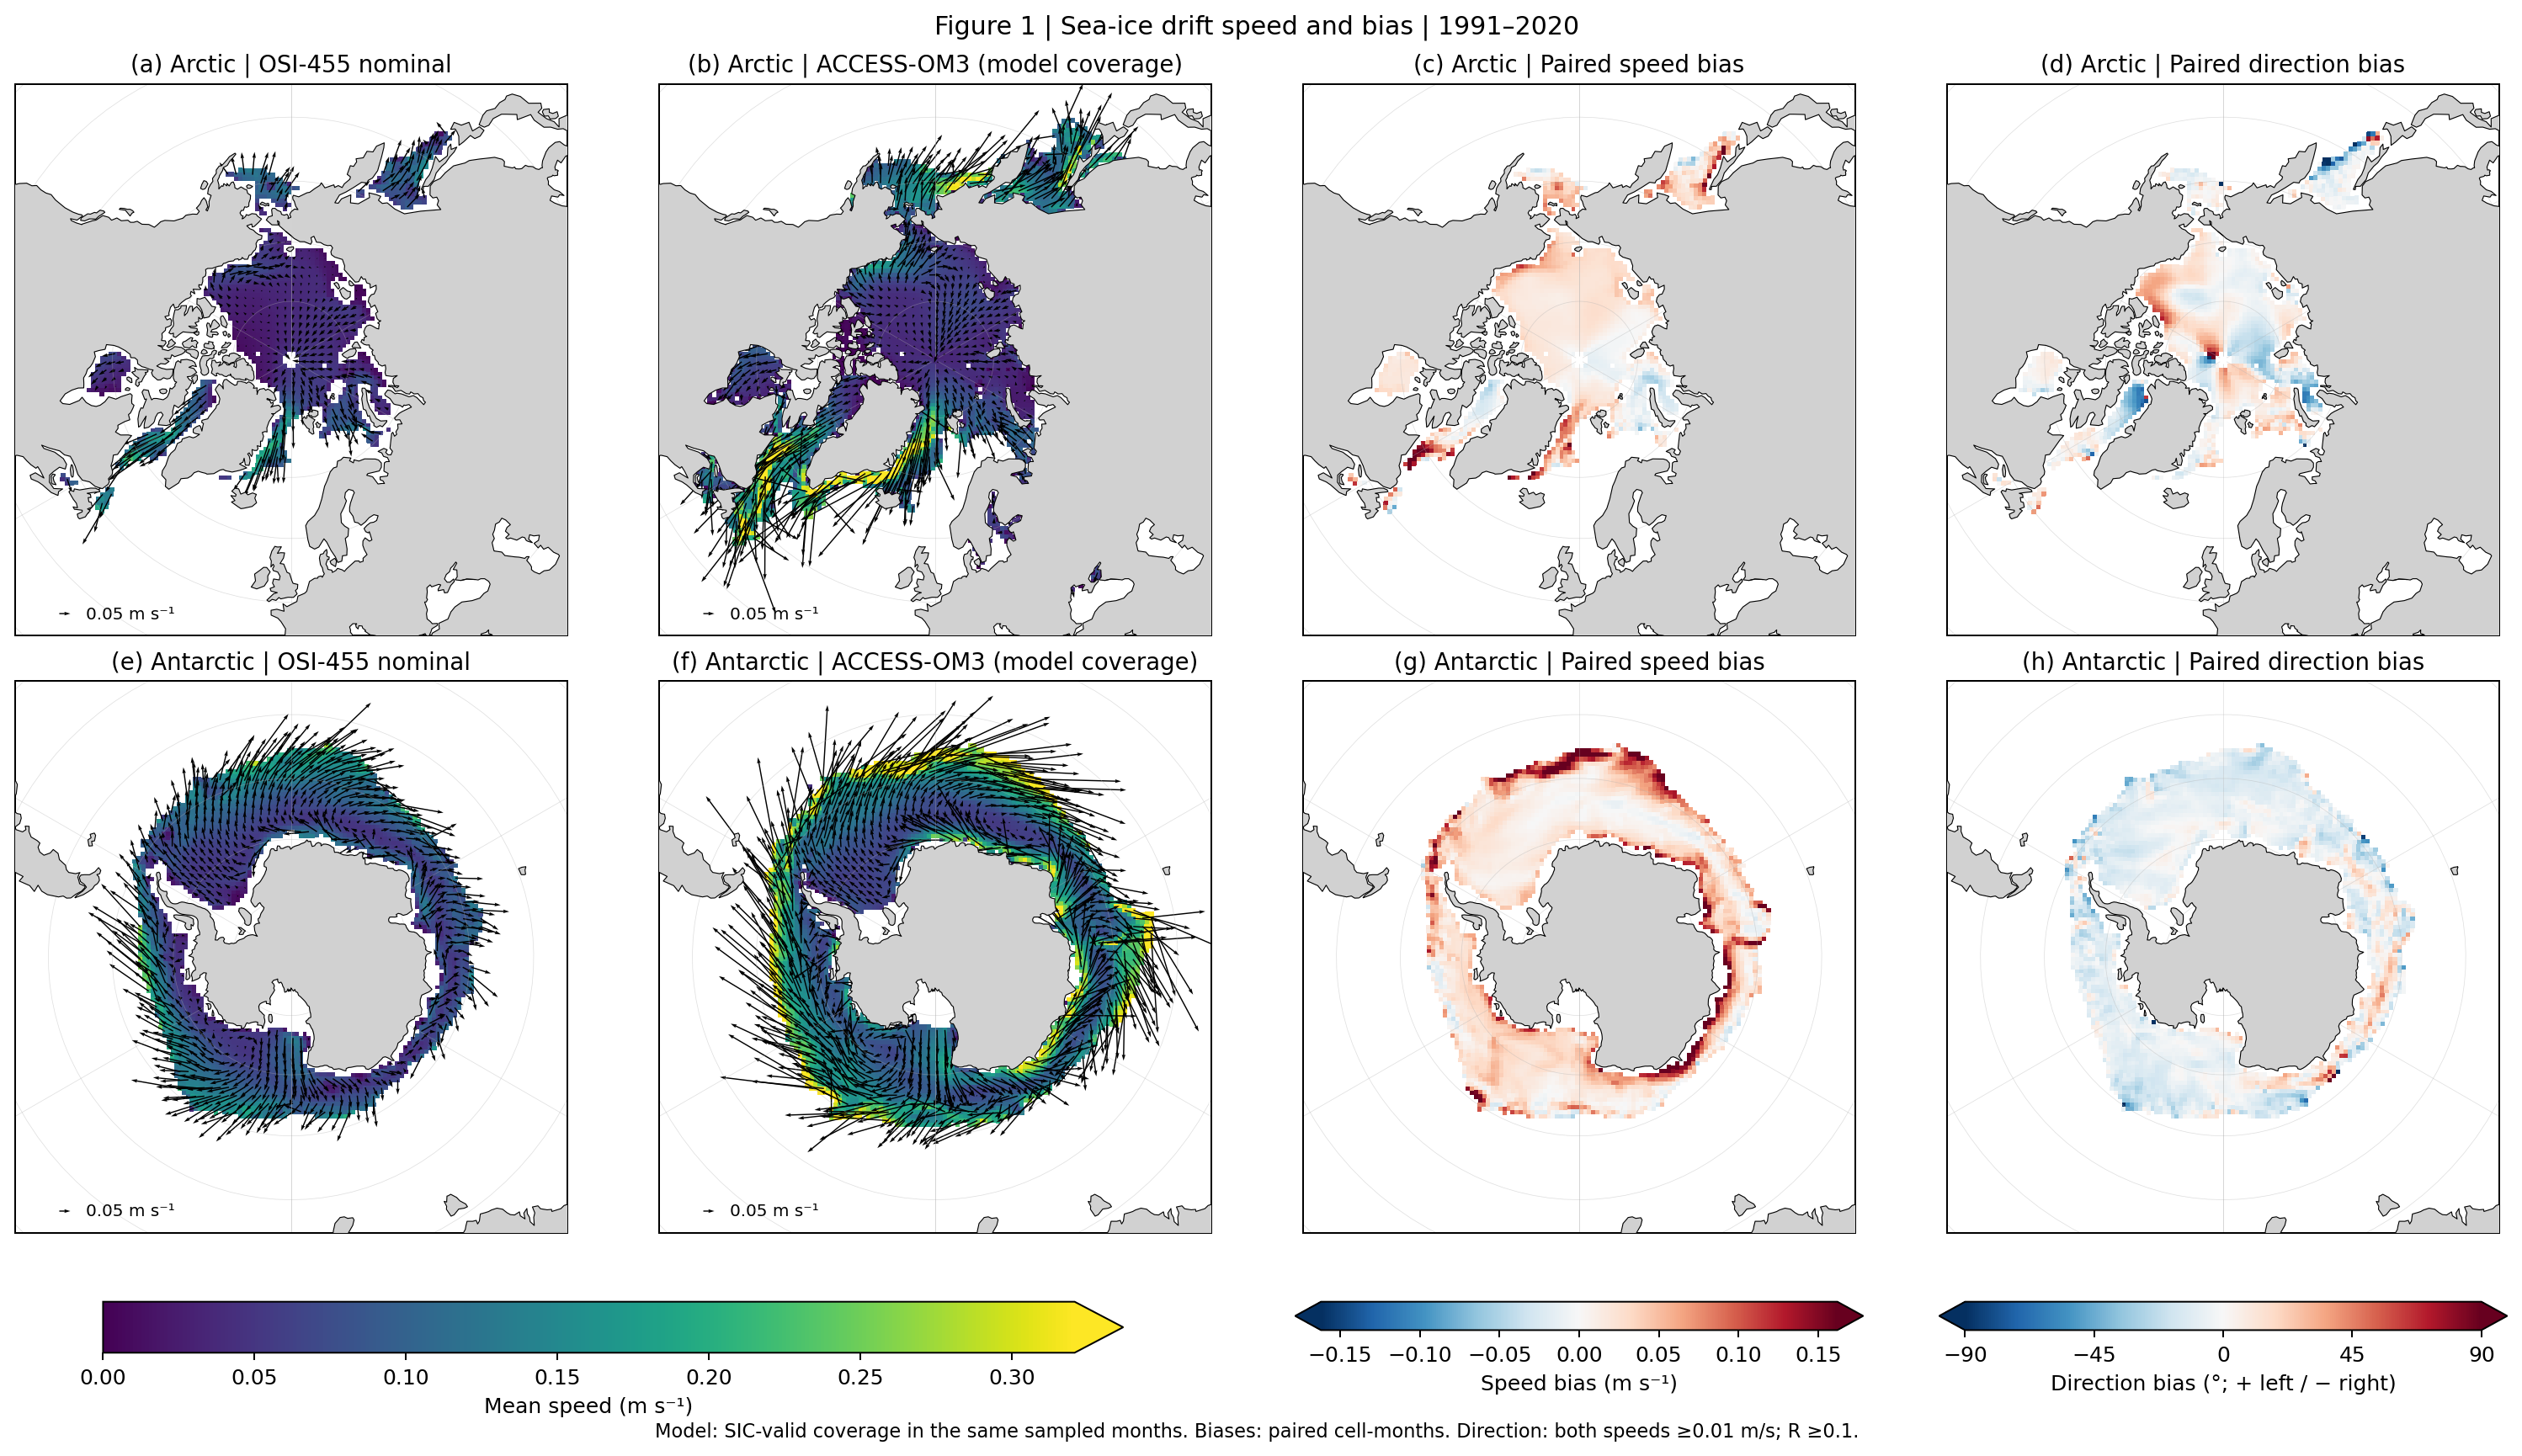

In [32]:
maps_by_hem = {}

model_by_hem = {}

direction_by_hem = {}

direction_args = args

for hem in ("nh", "sh"):
    with xr.open_dataset(root / "plot_data" / f"maps_{hem}.nc") as maps:
        if maps.attrs.get("weighting") != aggregate["weighting"]:
            raise ValueError("Map climatology weights do not match summary tables")
        maps_by_hem[hem] = maps.sel(quality="nominal", season="ALL").load()
    with xr.open_dataset(root / "plot_data" / f"model_spatial_coverage_{hem}.nc") as model_map:
        if model_map.attrs.get("signature") != aggregate["signature"]:
            raise ValueError("Independent model map configuration mismatch")
        model_by_hem[hem] = model_map.load()
    # The saved matched fields already share a geographic east/north basis.
    matched = load_matched(direction_args, hem).sel(quality="nominal", drop=True)
    direction_map = direction_bias_climatology(matched, direction_args, turning_min_resultant)
    direction_map.attrs.update(signature=aggregate["signature"], start_year=aggregate["start_year"],
                               end_year=aggregate["end_year"])
    save_netcdf(direction_map, root / "plot_data" / f"direction_bias_{hem}.nc")
    direction_by_hem[hem] = direction_map
    matched.close()

finite = np.concatenate([a for hem in ("nh", "sh") for a in
                         (maps_by_hem[hem].speed_obs.values.ravel(), model_by_hem[hem].speed_model.values.ravel())])

finite = finite[np.isfinite(finite)]

vmax = max(.03, float(np.quantile(finite, .98))) if len(finite) else .1

finite_bias = np.concatenate([abs(d.speed_bias.values.ravel()) for d in maps_by_hem.values()])

finite_bias = finite_bias[np.isfinite(finite_bias)]

bmax = max(.01, float(np.quantile(finite_bias, .98))) if len(finite_bias) else .05

fig = plt.figure(figsize=(17, 9.5), constrained_layout=True)

specs = fig.add_gridspec(2, 4)

speed_axes, bias_axes, direction_axes = [], [], []

for row, (hem, pole) in enumerate((("nh", "Arctic"), ("sh", "Antarctic"))):
    nominal = maps_by_hem[hem]
    for col, (name, title, cmap, lo, hi) in enumerate([
        ("speed_obs", "OSI-455 nominal", "viridis", 0, vmax),
        ("speed_model", "ACCESS-OM3 (model coverage)", "viridis", 0, vmax),
        ("speed_bias", "Paired speed bias", "RdBu_r", -bmax, bmax),
        ("direction_bias_deg", "Paired direction bias", "RdBu_r", -90, 90)]):
        ax = polar_axis(fig, specs[row, col], hem)
        panel_data = model_by_hem[hem] if col == 1 else direction_by_hem[hem] if col == 3 else nominal
        im = map_field(ax, panel_data, name, cmap, lo, hi)
        if col < 2:
            speed_axes.append(ax)
            speed_image = im
            source = "obs" if col == 0 else "model"
            step = quiver_step
            arrows = ax.quiver(panel_data.lon.values[::step, ::step], panel_data.lat.values[::step, ::step],
                      panel_data[f"u_{source}"].values[::step, ::step], panel_data[f"v_{source}"].values[::step, ::step],
                      transform=ccrs.PlateCarree(), scale=quiver_scale, scale_units="width",
                      width=quiver_width, color="black")
            ax.quiverkey(arrows, .10, .04, .05, "0.05 m s⁻¹", coordinates="axes", labelpos="E",
                         fontproperties={"size": 8})
        elif col == 2:
            bias_axes.append(ax)
            bias_image = im
        else:
            direction_axes.append(ax)
            direction_image = im
        ax.set_title(f"({chr(97+row*4+col)}) {pole} | {title}")

fig.colorbar(speed_image, ax=speed_axes, orientation="horizontal", shrink=.8,
             label="Mean speed (m s⁻¹)", extend="max")

fig.colorbar(bias_image, ax=bias_axes, orientation="horizontal", shrink=.9,
             label="Speed bias (m s⁻¹)", extend="both")

fig.colorbar(direction_image, ax=direction_axes, orientation="horizontal", shrink=.9,
             ticks=[-90, -45, 0, 45, 90], label="Direction bias (°; + left / − right)", extend="both")

fig.suptitle(f"Figure 1 | Sea-ice drift speed and bias | {period}")

fig.supxlabel("Model: SIC-valid coverage in the same sampled months. Biases: paired cell-months. "
               f"Direction: both speeds ≥{direction_args.direction_floor} m/s; R ≥{turning_min_resultant}.", fontsize=9)

save(fig, "both_poles_speed_and_bias", "Figure 1: both poles, sea-ice speed and bias",
     caption_base + f" Arctic above, Antarctic below; columns show OBS speed, model speed, paired speed bias and paired direction bias. "
     f"Speeds are means of monthly-vector magnitudes; arrows are mean east/north vectors sampled every {quiver_step} grid cells, "
     f"with identical scale={quiver_scale} (inverse length). Both poles share speed and zero-symmetric bias scales, "
     "using pooled 98th percentiles (minimum ranges 0.03/0.01 m s-1); triangles indicate saturation. "
     "Model panels b/f retain SIC-valid model fields independently of local OBS coverage during months "
     "with any nominal paired observations in that hemisphere. No extra summer months are added. "
     "Speed-bias panels c/g still use the original paired cell-month averages, so they are not a simple subtraction "
     "of the separately supported displayed climatologies. Direction panels d/h show SIC × month-duration weighted "
     "circular means of local monthly atan2(cross, dot) angles from OBS to model, not angles between climatological vectors. "
     f"Both speeds must be ≥{direction_args.direction_floor} m/s; cells with undefined angles or R <{turning_min_resultant} are blank. "
     "Positive is counterclockwise (model left); negative is clockwise (model right) in both hemispheres. "
     "Direction uses a common ±90-degree colour scale; triangles indicate angles beyond the displayed limits. "
     "Annual climatologies use available nominal coverage, not complete 12-month observations. All scalar statistics remain paired and unchanged.")

display(Image(filename=paths[-1]["path"]))


### Figure 2: Mean bias

Three rows: original all-paired result, SIC >80%, and 15% <SIC <80%; columns: Arctic and Antarctic. Strata use regridded monthly model SIC and identical membership for OBS and model. Strict subgroup bounds exclude exact 80% and 15%; the original overall result retains the existing SIC >=15% mask. Each panel uses area x model SIC x month-duration weights, paired nominal samples and the same direction-speed floor. All panels share speed and angular axes.


Saved /g/data/jk72/zc0441/ACCESS-OM3_evaluation_task/51_osi455_stage/quiet_outputs/paper/notebooks/mkfigs_output_MC_25km_jra_iaf+wombatlite-test4-d28e0359/mkmd/51_si_drift_osi455_02.png
Adding entry to per-notebook markdown: /g/data/jk72/zc0441/ACCESS-OM3_evaluation_task/51_osi455_stage/quiet_outputs/paper/notebooks/mkfigs_output_MC_25km_jra_iaf+wombatlite-test4-d28e0359/mkmd/51_si_drift_osi455.md
Lines appended to /g/data/jk72/zc0441/ACCESS-OM3_evaluation_task/51_osi455_stage/quiet_outputs/paper/notebooks/mkfigs_output_MC_25km_jra_iaf+wombatlite-test4-d28e0359/mkmd/51_si_drift_osi455.md successfully.


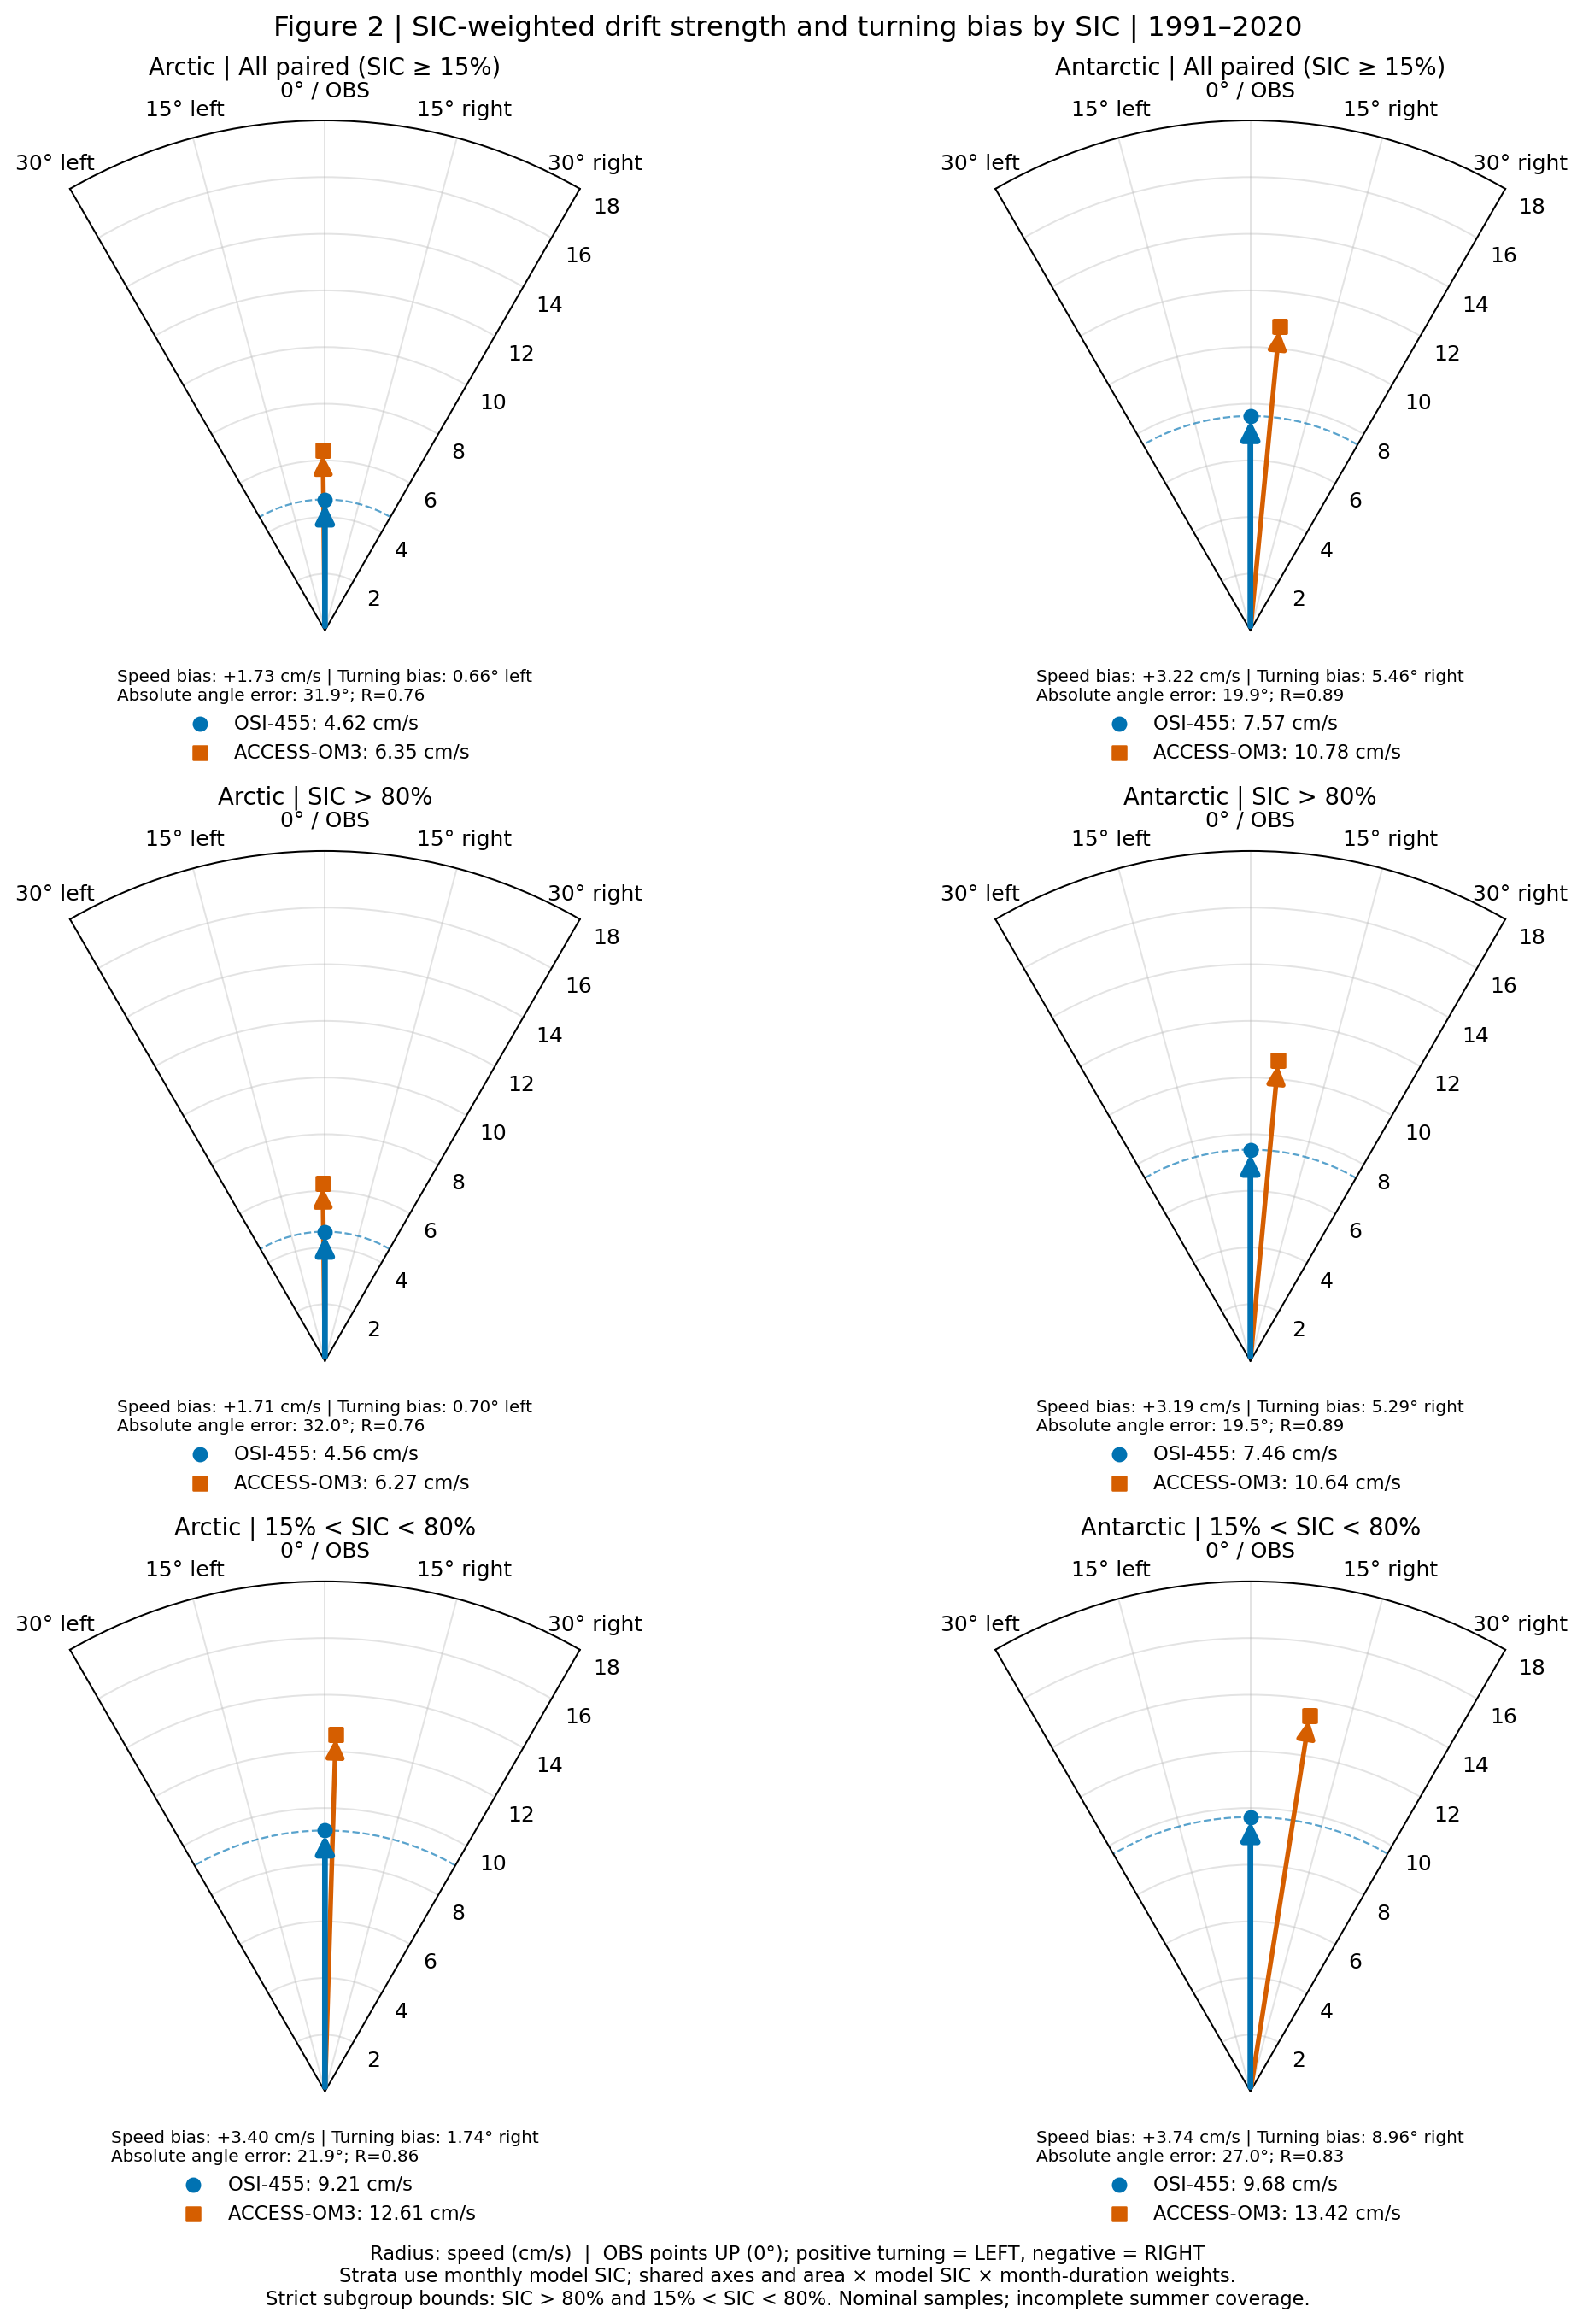

In [33]:
def velocity_cycle_by_sic(ds, args, hemisphere):
    """Apply SIC strata to paired monthly samples, identically for OBS/model."""
    groups = [
        ("all", f"All paired (SIC ≥ {args.sic_threshold:.0%})", None),
        ("sic_gt_80", "SIC > 80%", ds.aice_model > .8),
        ("sic_15_80", "15% < SIC < 80%", (ds.aice_model > .15) & (ds.aice_model < .8)),
    ]
    records = []
    for key, label, selection in groups:
        field = ds.copy(deep=False)
        if selection is not None:
            # Masking SIC makes common_mask reject exactly the same cells for both vectors.
            field["aice_model"] = ds.aice_model.where(selection)
        cycle = velocity_cycle_metrics(field, args)
        cycle["hemisphere"], cycle["quality"] = hemisphere, "nominal"
        cycle["sic_group"], cycle["sic_label"] = key, label
        records.append(cycle)
    return pd.concat(records, ignore_index=True)

def annual_velocity_by_sic(cycle):
    """Pool monthly circular moments separately within each SIC stratum."""
    records = []
    for (hem, group), rows in cycle.groupby(["hemisphere", "sic_group"], sort=False):
        if rows.n_grid_months.sum() > 0:
            annual = annual_velocity_metrics(rows)
        else:
            annual = pd.DataFrame([dict(hemisphere=hem, quality="nominal", obs_mean=np.nan,
                model_mean=np.nan, speed_bias=np.nan, turning_angle_deg=np.nan,
                direction_resultant=np.nan, direction_mae_deg=np.nan, n_grid_months=0,
                n_direction=0, covered_calendar_months=0)])
        annual["sic_group"], annual["sic_label"] = group, rows.sic_label.iloc[0]
        annual["paired_weight_m2_days"] = float(rows.paired_weight_m2_days.sum())
        annual["direction_weight_m2_days"] = float(rows.direction_weight_m2_days.sum())
        records.append(annual)
    return pd.concat(records, ignore_index=True)

def prepare_sic_sector_data(args, code_sha256=None):
    """Use saved matched fields only; keep original all-SIC tables untouched."""
    frames = []
    for hem in ("nh", "sh"):
        ds = load_matched(args, hem).sel(quality="nominal", drop=True)
        frames.append(velocity_cycle_by_sic(ds, args, hem))
        ds.close()
        del ds
    cycle = pd.concat(frames, ignore_index=True)
    annual = annual_velocity_by_sic(cycle)
    cycle_path = args.output_root / "tables/velocity_turning_sic_cycle.csv"
    annual_path = args.output_root / "tables/velocity_turning_annual_sic_groups.csv"
    cycle.to_csv(cycle_path, index=False)
    annual.to_csv(annual_path, index=False)
    write_json(args.output_root / "manifests/velocity_turning_sic_groups.json",
               dict(signature=signature(args), weighting="cell_area * model_SIC * calendar_month_days",
                    direction_floor=args.direction_floor, source="Saved matched monthly nominal fields",
                    sic_source="Regridded monthly model SIC; identical membership for OBS and model",
                    groups=["all", "sic_gt_80", "sic_15_80"],
                    subgroup_bounds="SIC > 0.80; 0.15 < SIC < 0.80. Exact 0.80 and 0.15 are excluded from subgroups.",
                    cycle_rows=len(cycle), annual_rows=len(annual),
                    cycle_sha256=hashlib.sha256(cycle_path.read_bytes()).hexdigest(),
                    annual_sha256=hashlib.sha256(annual_path.read_bytes()).hexdigest(),
                    code_sha256=code_sha256 if code_sha256 is not None else plot_source_sha256))
    return cycle, annual

cycle_path = root / "tables/velocity_turning_cycle.csv"

cycle = pd.read_csv(cycle_path)

annual = annual_velocity_metrics(cycle)

annual.to_csv(root / "tables/velocity_turning_annual.csv", index=False)

cycle_meta = json.loads((root / "manifests/velocity_turning_cycle.json").read_text())


write_json(root / "manifests/velocity_turning_annual.json",
           dict(signature=aggregate["signature"], source_cycle_sha256=hashlib.sha256(cycle_path.read_bytes()).hexdigest(),
                cycle_generation_code_sha256=cycle_meta["code_sha256"], rows=2,
                code_sha256=plot_source_sha256,
                statistic="Annual climatology pooled over available paired cell-months, not 12-month-complete coverage"))

sector_args = args

sic_cycle, sic_annual = prepare_sic_sector_data(sector_args, code_sha256=plot_source_sha256)

full_group = sic_annual[sic_annual.sic_group == "all"].reset_index(drop=True)

pd.testing.assert_frame_equal(full_group[annual.columns], annual, check_exact=False, rtol=1e-10, atol=1e-10)
if "sic_group" not in sic_annual:
    sic_annual = sic_annual.assign(sic_group="all", sic_label="All paired")

group_order = [key for key in ("all", "sic_gt_80", "sic_15_80") if key in set(sic_annual.sic_group)]

fig, axes = plt.subplots(len(group_order), 2, figsize=(12, 5*len(group_order)),
                         subplot_kw={"projection": "polar"}, squeeze=False, constrained_layout=True)

speeds = sic_annual[["obs_mean", "model_mean"]].to_numpy()

maximum = float(np.nanmax(speeds)) if np.isfinite(speeds).any() else 0.

radius_max = 2 * np.ceil(100 * maximum * 1.2 / 2)

radius_max = max(2., radius_max)

stable_angles = sic_annual.loc[sic_annual.direction_resultant >= turning_min_resultant, "turning_angle_deg"].dropna()

half_angle = max(30., float(np.ceil(stable_angles.abs().max() / 15) * 15 + 15)) if len(stable_angles) else 30.

half_angle = min(180., half_angle)

panels = [(axes[r, c], hem, title, group) for r, group in enumerate(group_order)
          for c, (hem, title) in enumerate((("nh", "Arctic"), ("sh", "Antarctic")))]

for ax, hem, title, group in panels:
    row = sic_annual[(sic_annual.hemisphere == hem) & (sic_annual.sic_group == group)].iloc[0]
    obs, model = 100 * row.obs_mean, 100 * row.model_mean
    ax.set_theta_zero_location("N")  # Reference observation points UP.
    ax.set_theta_direction(1)  # Positive = LEFT; negative = RIGHT, in both poles.
    ax.set_thetamin(-half_angle)
    ax.set_thetamax(half_angle)
    ticks = np.linspace(-half_angle, half_angle, 5)
    ax.set_thetagrids(ticks, labels=[f"{abs(t):g}° right" if t < 0 else
                                    f"{t:g}° left" if t > 0 else "0° / OBS"
                                    for t in ticks])
    ax.set_ylim(0, radius_max)
    ax.set_rticks(np.arange(2, radius_max+1, 2))
    ax.set_rlabel_position(half_angle)
    ax.grid(alpha=.35)
    ax.set_title(f"{title} | {row.sic_label}", pad=22)
    if not np.isfinite(obs) or not np.isfinite(model):
        ax.text(.5, .5, "No qualifying paired samples", transform=ax.transAxes, ha="center")
        continue
    ax.annotate("", xy=(0, obs), xytext=(0, 0),
                arrowprops=dict(arrowstyle="-|>", color="#0072B2", lw=2.7, mutation_scale=17), zorder=5)
    ax.scatter([0], [obs], s=38, color="#0072B2", marker="o", label=f"OSI-455: {obs:.2f} cm/s", zorder=6)
    stable = np.isfinite(row.turning_angle_deg) and row.direction_resultant >= turning_min_resultant
    if stable:
        theta = np.deg2rad(row.turning_angle_deg)
        ax.annotate("", xy=(theta, model), xytext=(0, 0),
                    arrowprops=dict(arrowstyle="-|>", color="#D55E00", lw=2.2, mutation_scale=17), zorder=4)
        ax.scatter([theta], [model], s=38, color="#D55E00", marker="s", label=f"ACCESS-OM3: {model:.2f} cm/s", zorder=6)
        # A reference arc lets radial (speed) and angular departures be read separately.
        ax.plot(np.linspace(-half_angle, half_angle, 161) * np.pi/180, np.full(161, obs),
                color="#0072B2", lw=.9, ls="--", alpha=.65)
        side = "left" if row.turning_angle_deg > 0 else "right" if row.turning_angle_deg < 0 else "aligned"
        turning_text = f"Turning bias: {abs(row.turning_angle_deg):.2f}° {side}"
    else:
        turning_text = "Turning bias: unstable (model arrow hidden)"
    ax.legend(loc="upper center", bbox_to_anchor=(.5, -.04), frameon=False, fontsize=9,
              title=f"Speed bias: {100*row.speed_bias:+.2f} cm/s | {turning_text}\n"
                    f"Absolute angle error: {row.direction_mae_deg:.1f}°; R={row.direction_resultant:.2f}",
              title_fontsize=8)
    if max(obs, model) > ax.get_ylim()[1]:
        raise AssertionError("Annual speed arrow clipped by radial axis")

fig.suptitle(f"Figure 2 | SIC-weighted drift strength and turning bias by SIC | {period}", fontsize=13)

fig.supxlabel("Radius: speed (cm/s)  |  OBS points UP (0°); positive turning = LEFT, negative = RIGHT\n"
               "Strata use monthly model SIC; shared axes and area × model SIC × month-duration weights.\n"
               "Strict subgroup bounds: SIC > 80% and 15% < SIC < 80%. Nominal samples; incomplete summer coverage.", fontsize=9)
save(fig, "both_poles_velocity_turning_annual_sector", "Both poles: annual velocity and turning sector diagram",
     caption_base + " Annual climatology pools all available nominal paired cell-months using area × model SIC × month-duration weights. "
     "Radius is mean speed in cm/s. The observation arrow is defined at 0 degrees; the model angle is the circular mean "
     "of local observation-to-model turning: observation points UP, positive turning LEFT and negative RIGHT. "
     "These are relative directions, NOT geographic direction or ice relative to wind. "
     "The arrows combine two summary statistics and do not represent a spatially averaged physical velocity vector; "
     "their endpoint separation is not vector RMSE. Monthly circular moments retain their resultant lengths when pooled. "
     f"Angles require both speeds ≥{cycle_meta['direction_floor']} m/s; model arrows with R <{turning_min_resultant} are hidden. "
     "The dashed observation-speed arc separates radial and angular bias. Absolute angular error is annotated to expose cancellation. "
     "Summer gaps are not filled: annual means describe available coverage, not an independently observed complete year. "
     "Three rows show all paired SIC-valid samples, SIC >80%, and 15% <SIC <80%; columns are Arctic and Antarctic. "
     "SIC strata use monthly model SIC after regridding, with identical membership for OBS and model. "
     "Subgroup inequalities are strict: exact 80% and 15% are excluded from both subgroups; the original overall result is retained. "
     "All six panels share radial and angular scales.")

sector_table = sic_annual[["hemisphere", "sic_label", "obs_mean", "model_mean", "speed_bias",
                           "turning_angle_deg", "direction_resultant", "direction_mae_deg", "n_grid_months"]]
if show_details:
    mkmd.table("Annual sector statistics", sector_table.round(5).to_markdown(index=False).split("\n"))
if show_details:
    display(sector_table)
archived_annual = pd.read_csv(output_root / "tables/velocity_turning_annual.csv")
pd.testing.assert_frame_equal(annual, archived_annual, check_exact=False, rtol=1e-10, atol=1e-10)
if show_details:
    print("Visible annual circular moments reproduce the archived sector statistics.")
display(Image(filename=paths[-1]["path"]))


### Figure 3: Seasonality


Saved /g/data/jk72/zc0441/ACCESS-OM3_evaluation_task/51_osi455_stage/quiet_outputs/paper/notebooks/mkfigs_output_MC_25km_jra_iaf+wombatlite-test4-d28e0359/mkmd/51_si_drift_osi455_03.png
Adding entry to per-notebook markdown: /g/data/jk72/zc0441/ACCESS-OM3_evaluation_task/51_osi455_stage/quiet_outputs/paper/notebooks/mkfigs_output_MC_25km_jra_iaf+wombatlite-test4-d28e0359/mkmd/51_si_drift_osi455.md
Lines appended to /g/data/jk72/zc0441/ACCESS-OM3_evaluation_task/51_osi455_stage/quiet_outputs/paper/notebooks/mkfigs_output_MC_25km_jra_iaf+wombatlite-test4-d28e0359/mkmd/51_si_drift_osi455.md successfully.


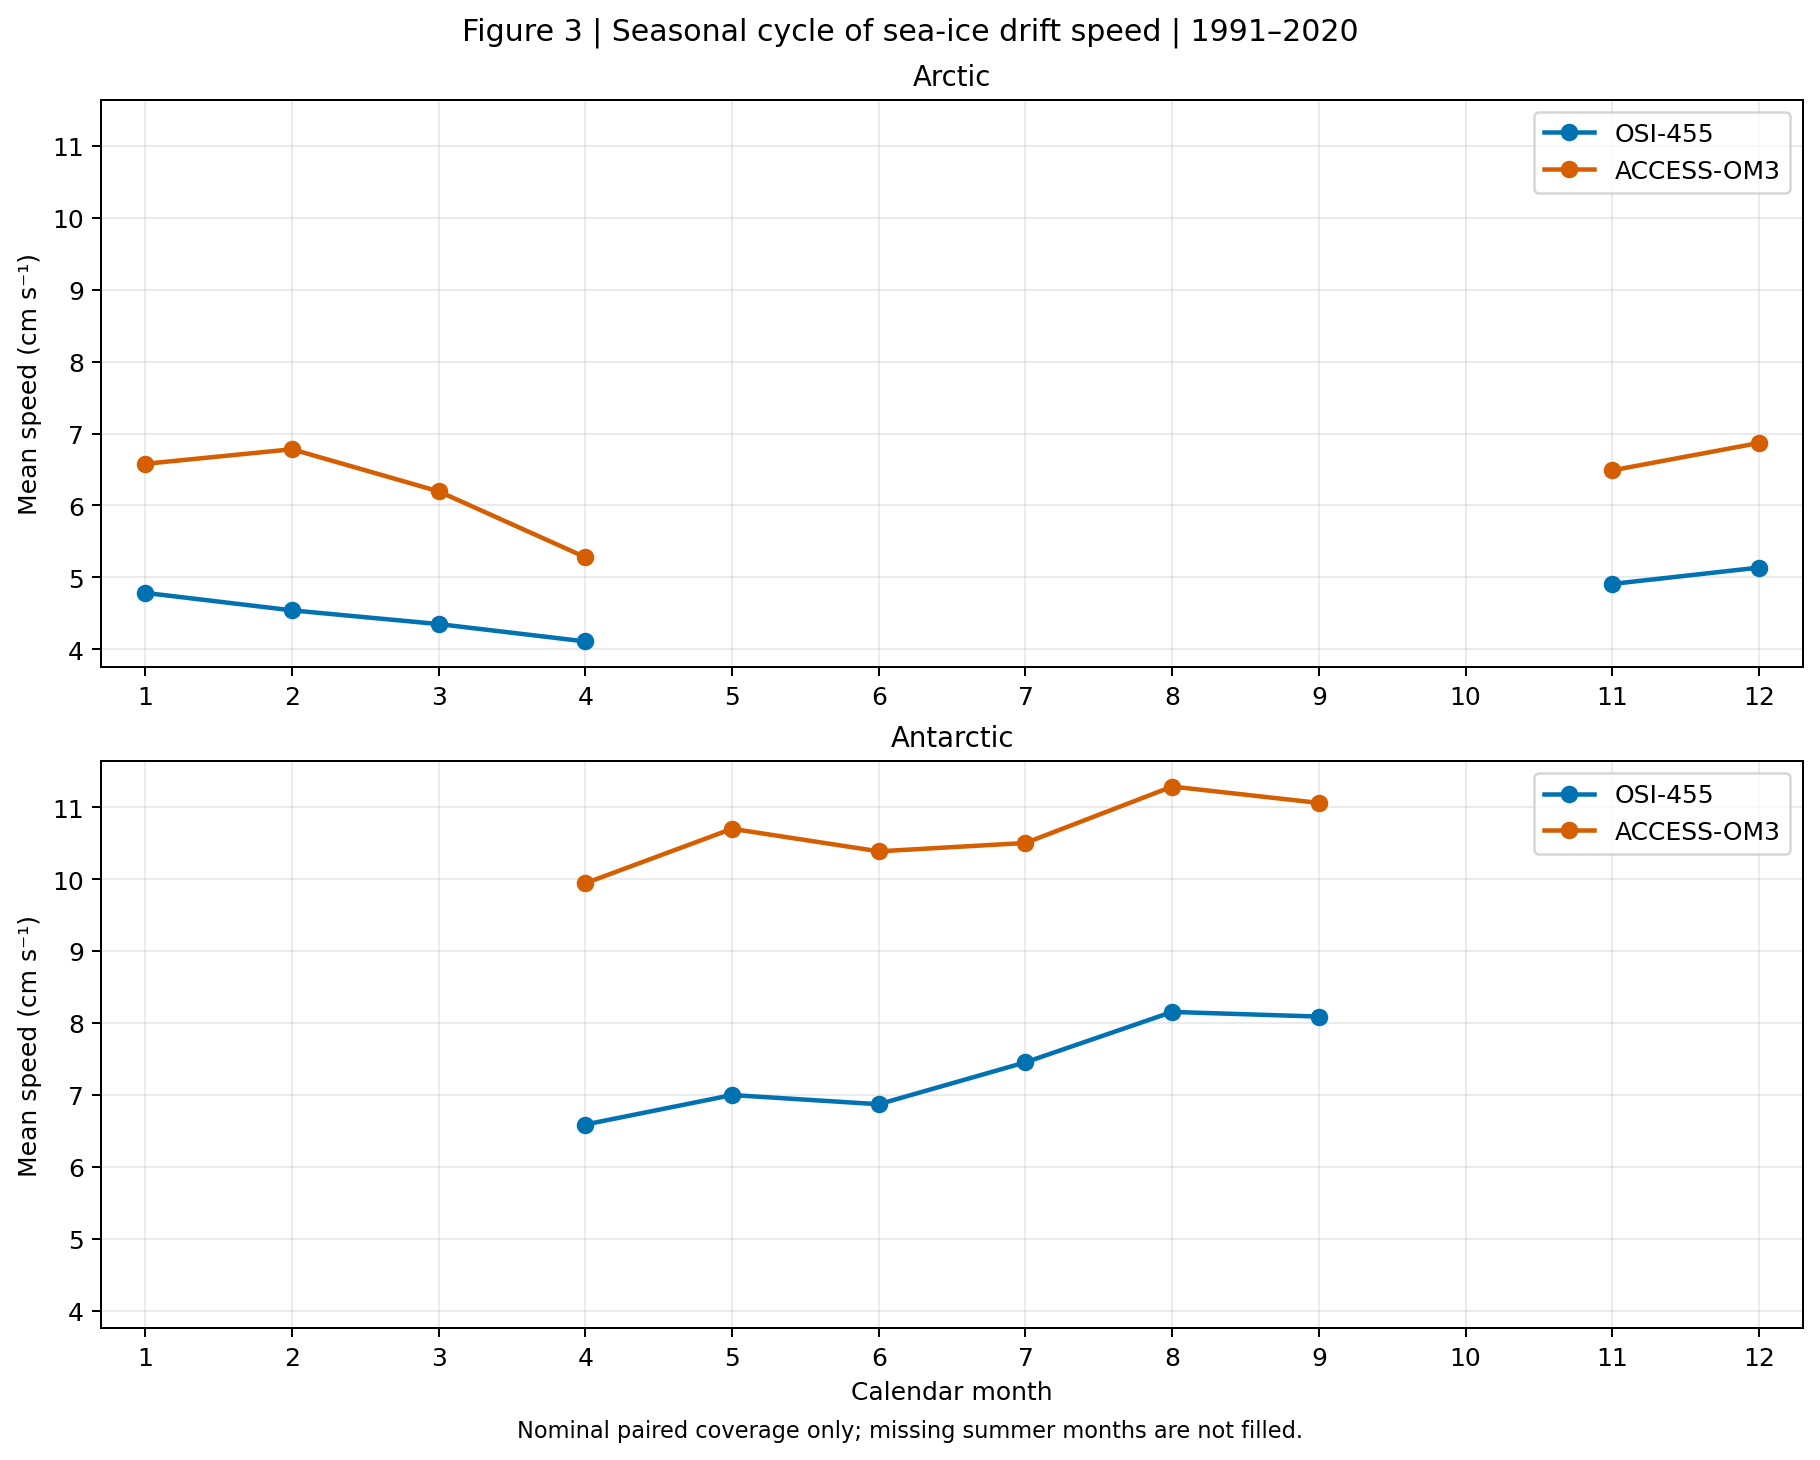

In [34]:
cycle = pd.read_csv(root / "tables/velocity_turning_cycle.csv")

fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True, sharey=True, constrained_layout=True)

for ax, (hem, pole) in zip(axes, (("nh", "Arctic"), ("sh", "Antarctic"))):
    rows = cycle[cycle.hemisphere == hem].set_index("month").reindex(range(1, 13))
    for source, label, color in (("obs", "OSI-455", "#0072B2"), ("model", "ACCESS-OM3", "#D55E00")):
        ax.plot(rows.index, 100*rows[f"{source}_mean"], marker="o", lw=1.8, color=color, label=label)
    ax.set(title=pole, ylabel="Mean speed (cm s⁻¹)", xticks=range(1, 13), xlim=(.7, 12.3))
    ax.tick_params(labelbottom=True)
    ax.grid(alpha=.25)
    ax.legend(loc="upper right")

axes[-1].set_xlabel("Calendar month")

fig.suptitle(f"Figure 3 | Seasonal cycle of sea-ice drift speed | {period}")

fig.supxlabel("Nominal paired coverage only; missing summer months are not filled.", fontsize=9)

save(fig, "both_poles_seasonality", "Figure 3: seasonal speed cycle, OBS versus model",
     caption_base + " Two rows, one column: Arctic above Antarctic. Each calendar month pools paired cell-months "
     "across years with area × model SIC × month-duration weights, not an unweighted mean of regional means. "
     "Missing months remain NaN gaps; no wind-derived observations or interpolation fill the gaps.")

display(Image(filename=paths[-1]["path"]))


### Figure 4: Trend (1991-2020)


Saved /g/data/jk72/zc0441/ACCESS-OM3_evaluation_task/51_osi455_stage/quiet_outputs/paper/notebooks/mkfigs_output_MC_25km_jra_iaf+wombatlite-test4-d28e0359/mkmd/51_si_drift_osi455_04.png
Adding entry to per-notebook markdown: /g/data/jk72/zc0441/ACCESS-OM3_evaluation_task/51_osi455_stage/quiet_outputs/paper/notebooks/mkfigs_output_MC_25km_jra_iaf+wombatlite-test4-d28e0359/mkmd/51_si_drift_osi455.md
Lines appended to /g/data/jk72/zc0441/ACCESS-OM3_evaluation_task/51_osi455_stage/quiet_outputs/paper/notebooks/mkfigs_output_MC_25km_jra_iaf+wombatlite-test4-d28e0359/mkmd/51_si_drift_osi455.md successfully.


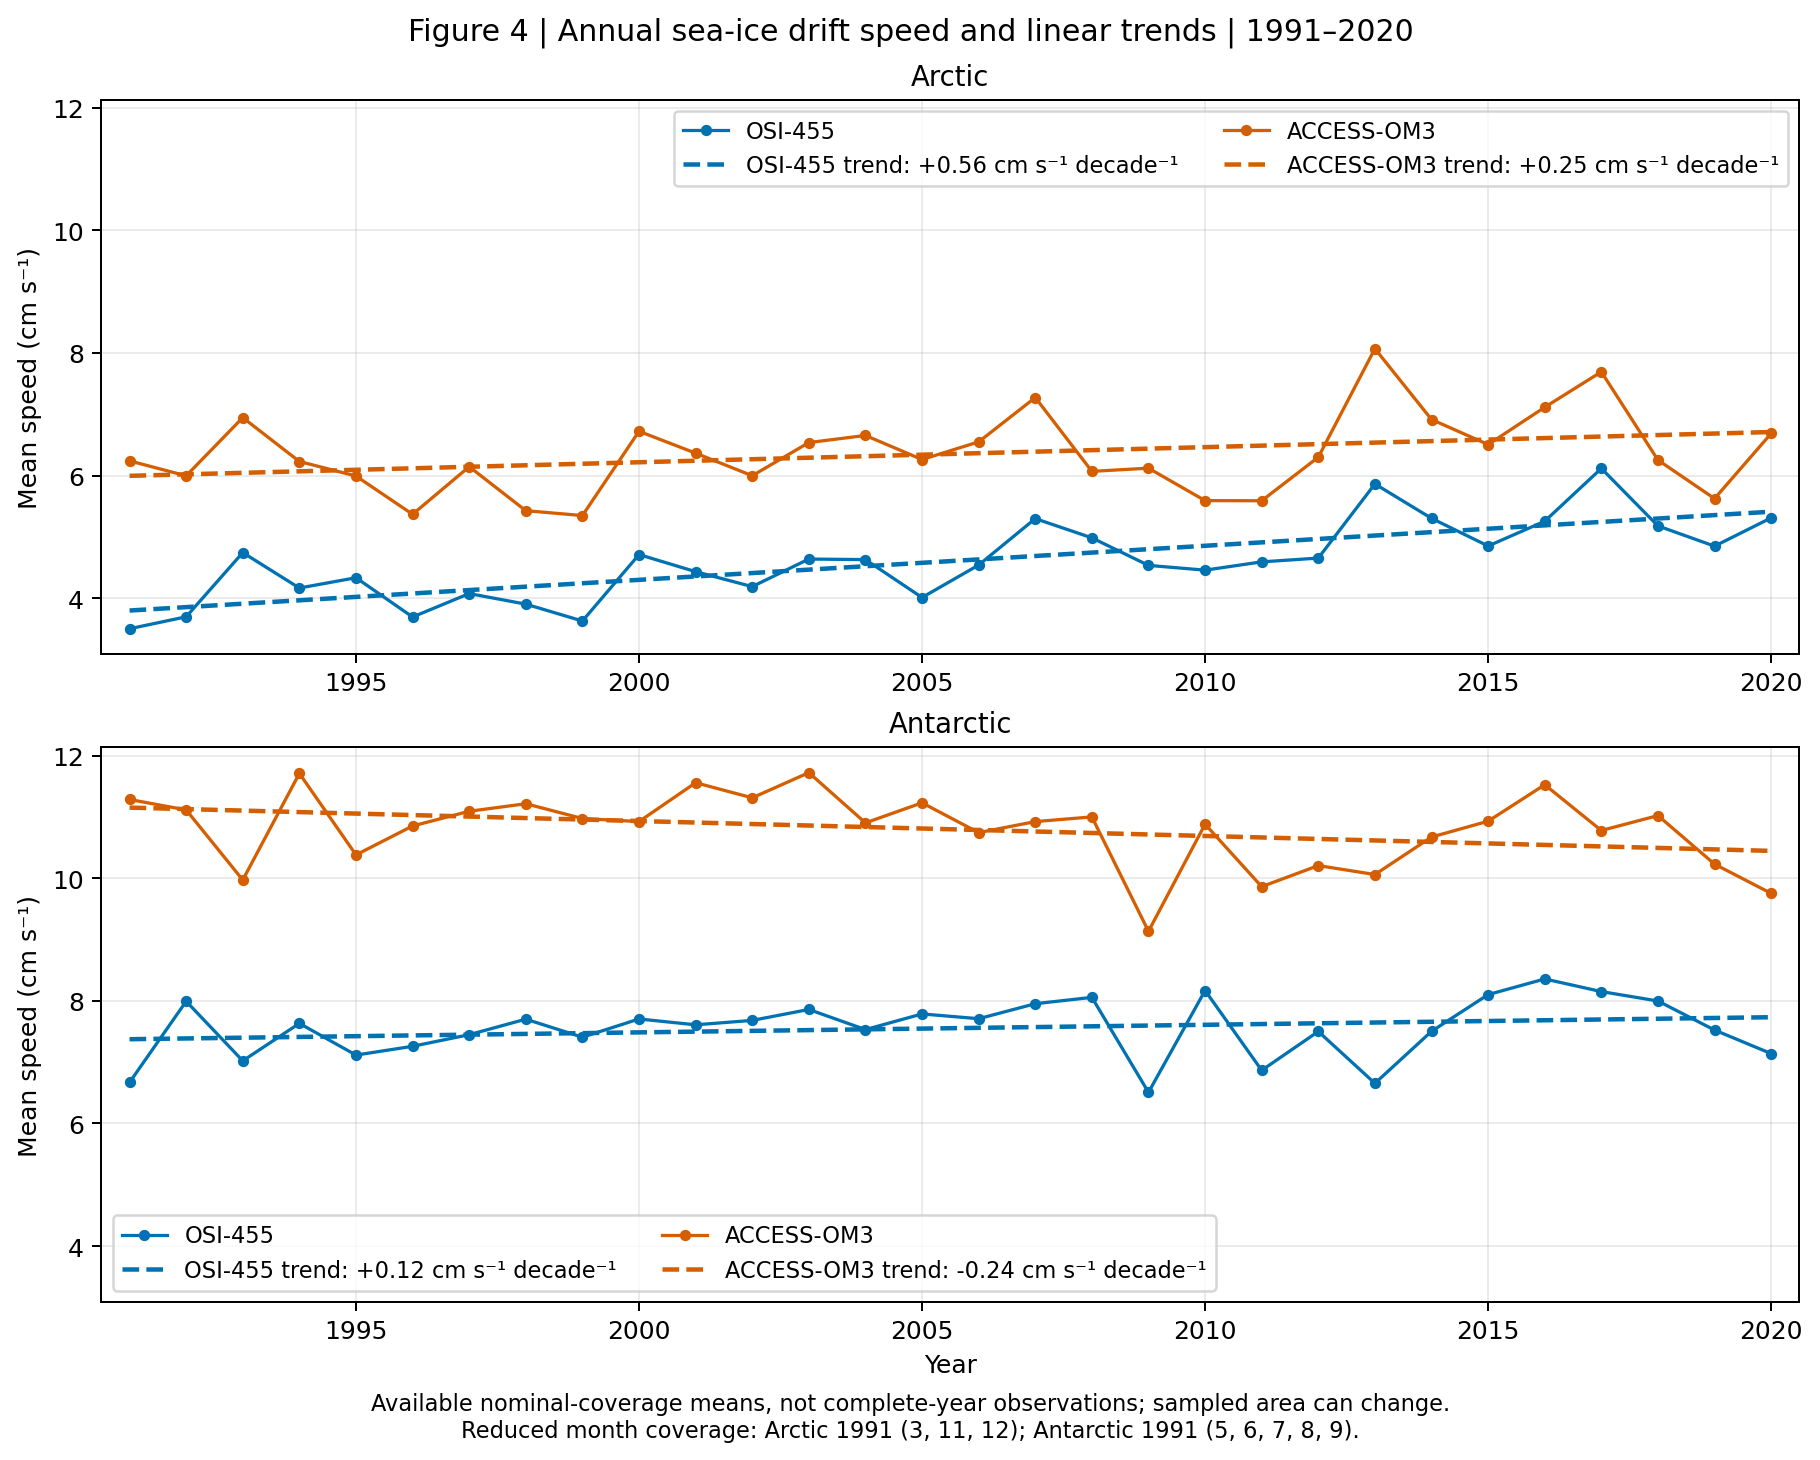

In [35]:
series_path = root / "tables/annual_speed_timeseries.csv"

series_meta = json.loads((root / "manifests/annual_speed_timeseries.json").read_text())

if (series_meta["signature"] != aggregate["signature"] or series_meta["weighting"] != aggregate["weighting"]
        or series_meta["table_sha256"] != hashlib.sha256(series_path.read_bytes()).hexdigest()):
    raise ValueError("Annual speed series provenance does not match this evaluation")

series = pd.read_csv(series_path)

expected_years = set(range(aggregate["start_year"], aggregate["end_year"]+1))

if not series.quality.eq("nominal").all() or any(set(g.year) != expected_years for _, g in series.groupby("hemisphere")):
    raise ValueError("Trend series must contain the full requested years with nominal paired coverage")

trends = speed_trends(series)

trends.to_csv(root / "tables/speed_trends.csv", index=False)


coverage = {hem: dict(covered_month_sets=sorted(g.covered_months.fillna("").unique().tolist()),
                     n_covered_months_min=int(g.n_covered_months.min()),
                     n_covered_months_max=int(g.n_covered_months.max()),
                     paired_fraction_min=float(g.valid_ice_fraction.min()),
                     paired_fraction_max=float(g.valid_ice_fraction.max()))
            for hem, g in series.groupby("hemisphere")}

write_json(root / "manifests/speed_trends.json",
           dict(signature=aggregate["signature"], weighting=aggregate["weighting"], coverage=coverage,
                code_sha256=plot_source_sha256,
                source_series_sha256=hashlib.sha256(series_path.read_bytes()).hexdigest(),
                fitting="Equal-year ordinary least squares on available-coverage yearly mean speeds; descriptive slopes, no CI/p-value"))

fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True, sharey=True, constrained_layout=True)

reduced_coverage = []

for ax, (hem, pole) in zip(axes, (("nh", "Arctic"), ("sh", "Antarctic"))):
    rows = series[series.hemisphere == hem].sort_values("year")
    for _, row in rows[rows.n_covered_months < rows.n_covered_months.max()].iterrows():
        reduced_coverage.append(f"{pole} {int(row.year)} ({row.covered_months.replace(';', ', ')})")
    for source, label, color in (("obs", "OSI-455", "#0072B2"), ("model", "ACCESS-OM3", "#D55E00")):
        fit = trends[(trends.hemisphere == hem) & (trends.source == source)].iloc[0]
        ax.plot(rows.year, 100*rows[f"{source}_mean"], "o-", ms=3.5, lw=1.3, color=color, label=label)
        prediction = fit.intercept_m_s + fit.slope_m_s_per_year*(rows.year-fit.reference_year)
        ax.plot(rows.year, 100*prediction, "--", lw=1.8, color=color,
                label=f"{label} trend: {fit.slope_cm_s_per_decade:+.2f} cm s⁻¹ decade⁻¹")
    ax.set(title=pole, ylabel="Mean speed (cm s⁻¹)")
    ax.tick_params(labelbottom=True)
    ax.grid(alpha=.25)
    ax.legend(loc="best", fontsize=9, ncol=2)

axes[-1].set(xlabel="Year", xlim=(aggregate["start_year"]-.5, aggregate["end_year"]+.5))

fig.suptitle(f"Figure 4 | Annual sea-ice drift speed and linear trends | {period}")

coverage_note = "Reduced month coverage: " + "; ".join(reduced_coverage) + "." if reduced_coverage else ""

fig.supxlabel("Available nominal-coverage means, not complete-year observations; sampled area can change.\n"
               + coverage_note, fontsize=9)

save(fig, "both_poles_speed_trend", "Figure 4: annual speeds and trends, OBS versus model",
     caption_base + " Two rows, one column: Arctic above Antarctic. Yearly values pool available paired cell-months "
     "with common area × model SIC × month-duration weights. Dashed lines are equal-year OLS; slopes are descriptive, "
     "in cm/s per decade, without significance claims. Annual coverage is audited in annual_speed_timeseries.csv "
     "and speed_trends.json; changing sampled area/months can affect slopes. Not complete 12-month annual means. "
     + coverage_note)

(root / "manifests/figure_inventory.json").write_text(json.dumps(paths, indent=2) + "\n")

figures = paths
if show_details:
    print(f"Saved {len(figures)} figures through MkmdWriter and to the persistent figure directory.")
display(Image(filename=paths[-1]["path"]))


## Citation and limitations

EUMETSAT OSI SAF, Global Low Resolution Sea Ice Drift data record 1991–2020
(v1, 2022), OSI-455, doi:10.15770/EUM_SAF_OSI_0012, CC BY 4.0.

Monthly reference sampling is restricted by quality and observing conditions;
the model is a full-month mean. Daily-window pilot values are overlap-weighted
Eulerian daily means at the observed start grid, not model particle trajectories.
No confidence interval is inferred from averaged daily uncertainty. No OM2 run
or new model simulation is required for this evaluation.
